In [2]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

from pathlib import Path
import polars as pl
from matplotlib import pyplot as plt
import numpy as np
import shap

plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')

# Training dataset

In [3]:
training_set = 'training_df_try8'
df_training_set = pl.read_parquet(plato_data_directory / f"{training_set}.parquet").select(['path', 'label', 'GaiaID'])#.rename({'FilePath': 'path'})
print(df_training_set.height, df_training_set.columns)
df_training_set.group_by('label').len().sort('label')

26188 ['path', 'label', 'GaiaID']


label,len
str,u32
"""APERIODIC""",1521
"""CONTACT_ROT""",3331
"""DSCT_BCEP""",6534
"""ECLIPSE""",1157
"""GDOR_SPB""",4206
"""INSTRUMENT/JUNK""",5691
"""RRLYR_CEPH""",1174
"""SOLARLIKE""",2574


In [7]:
#sanity check
df_training_set['path'].is_duplicated().sum()

0

# Features and data partitions

In [8]:
from training import prepare_features_for_classification
from joblib import dump

save_path = Path('../results/classifications') / training_set
save_path.mkdir(exist_ok=True, parents=True)

# Loading features
df_training_features = pl.read_parquet(Path('../results/features/') / training_set)
print(df_training_features.height)
df_training_features = df_training_features.drop_nans().drop_nulls()
print(df_training_features.height)
df_training_features = df_training_features.join(df_training_set.select(['path', 'label', 'GaiaID']), on='path')
print(df_training_features.height)
df_training_features = df_training_features.filter(pl.col('num_negative_fluxes').eq(0))
print(df_training_features.height)

# Log transforms for features with large dynamic range
log_columns = [
    'flux_std', 'flux_iqr', 'flux_amplitude', 'flux_mad', 'flux_amplitude', 'flux_largest_departure', 'flux_percent_difference', 'max_slope',
    'ls_frequency_fundamental', 'ls_amplitude_fundamental', 'ls_fap_fundamental', 'ls_flatness',  'ls_amplitude_ratio_half_fundamental',
    '^ls_amplitude_ratio_top._fundamental$', '^fourier_amplitude_.$', 
]

asinh_columns = ['flux_skewness', 'flux_kurtosis']

drop_columns = [
    'num_negative_fluxes', '^ls_frequency_top.$',  #diagnostics features
    '^ls_distance_to_fundamental_harmonic_top.$', '^ls_closest_harmonic_top.$',
    #'^ls_amplitude_ratio_top._fundamental$', '^acf_lag_peak.$', '^acf_val_peak.$', 'acf_val_lag1', 'acf_lag_first_below_05', 'ls_entropy', 'ls_flatness', # new features
    'CO_trev_3_num', 'SP_Summaries_welch_rect_peakPower_5', 'ST_LocalExtrema_n100_medianmax', 'AC_nl_001', # Barbara et al.
]
feature_config = {'log_columns': log_columns, 'asinh_columns': asinh_columns, 'drop_columns': drop_columns}
with open(save_path / 'feature_config.pkl', "wb") as f:
    dump(feature_config, f, protocol=5)

df_training_features, df_dropped_features = prepare_features_for_classification(df_training_features, **feature_config)
df_training_features.columns, df_dropped_features.columns

26148
26148
26148
26147


(['flux_std',
  'flux_skewness',
  'flux_kurtosis',
  'flux_iqr',
  'flux_amplitude',
  'flux_mad',
  'flux_largest_departure',
  'flux_percent_difference',
  'flux_ratio_mid20',
  'flux_ratio_mid45',
  'flux_ratio_mid50',
  'flux_ratio_mid65',
  'flux_ratio_mid80',
  'max_slope',
  'acf_lag_first_below_05',
  'acf_val_lag1',
  'acf_lag_peak1',
  'acf_val_peak1',
  'acf_lag_peak2',
  'acf_val_peak2',
  'ls_frequency_fundamental',
  'ls_amplitude_fundamental',
  'ls_fap_fundamental',
  'ls_entropy',
  'ls_flatness',
  'ls_amplitude_ratio_half_fundamental',
  'ls_amplitude_ratio_top2_fundamental',
  'ls_amplitude_ratio_top3_fundamental',
  'ls_amplitude_ratio_top4_fundamental',
  'fourier_amplitude_1',
  'fourier_amplitude_2',
  'fourier_amplitude_3',
  'fourier_amplitude_4',
  'fourier_relative_phase_2',
  'fourier_relative_phase_3',
  'fourier_relative_phase_4',
  'fourier_r2_fit',
  'path',
  'label',
  'GaiaID'],
 ['path',
  'num_negative_fluxes',
  'ls_frequency_top2',
  'ls_frequen

In [9]:
# Train test split based on tics rather than on paths
#from sklearn.model_selection import train_test_split
#tic, y = df_training_features.unique('GaiaID')[['GaiaID', 'label']].sort('GaiaID').to_numpy().T
#print(df_training_set.height, df_training_set.columns)
#df_training_set.group_by('label').len().sort('label')
#tic_train, tic_test, _, _ = train_test_split(tic, y, stratify=y, test_size=0.3, random_state=1234, shuffle=True)

# Use same partitions as neural net
ids_train = pl.read_csv(plato_data_directory / f"{training_set}_train_gaiaids.csv").to_series().to_list()
ids_val = pl.read_csv(plato_data_directory / f"{training_set}_val_gaiaids.csv").to_series().to_list()
ids_fit = ids_train + ids_val
ids_test = pl.read_csv(plato_data_directory / f"{training_set}_test_gaiaids.csv").to_series().to_list()

def df_to_numpy(df):
    paths = df['path'].to_numpy()
    y = df['label'].to_numpy()
    X = df.drop(['GaiaID', 'path', 'label']).to_numpy()
    return X, y, paths

df_fit = df_training_features.filter(pl.col('GaiaID').is_in(ids_fit))
X_names = np.array(df_fit.drop(['GaiaID', 'path', 'label']).columns)
X_fit, y_fit, path_fit = df_to_numpy(df_fit)
groups_fit = df_fit['GaiaID'].to_numpy() # This will be used for group cv strategy
y_names = np.unique(y_fit)
df_test = df_training_features.filter(pl.col('GaiaID').is_in(ids_test))
X_test, y_test, path_test = df_to_numpy(df_test)
X_fit.shape, X_test.shape

((20986, 37), (5161, 37))

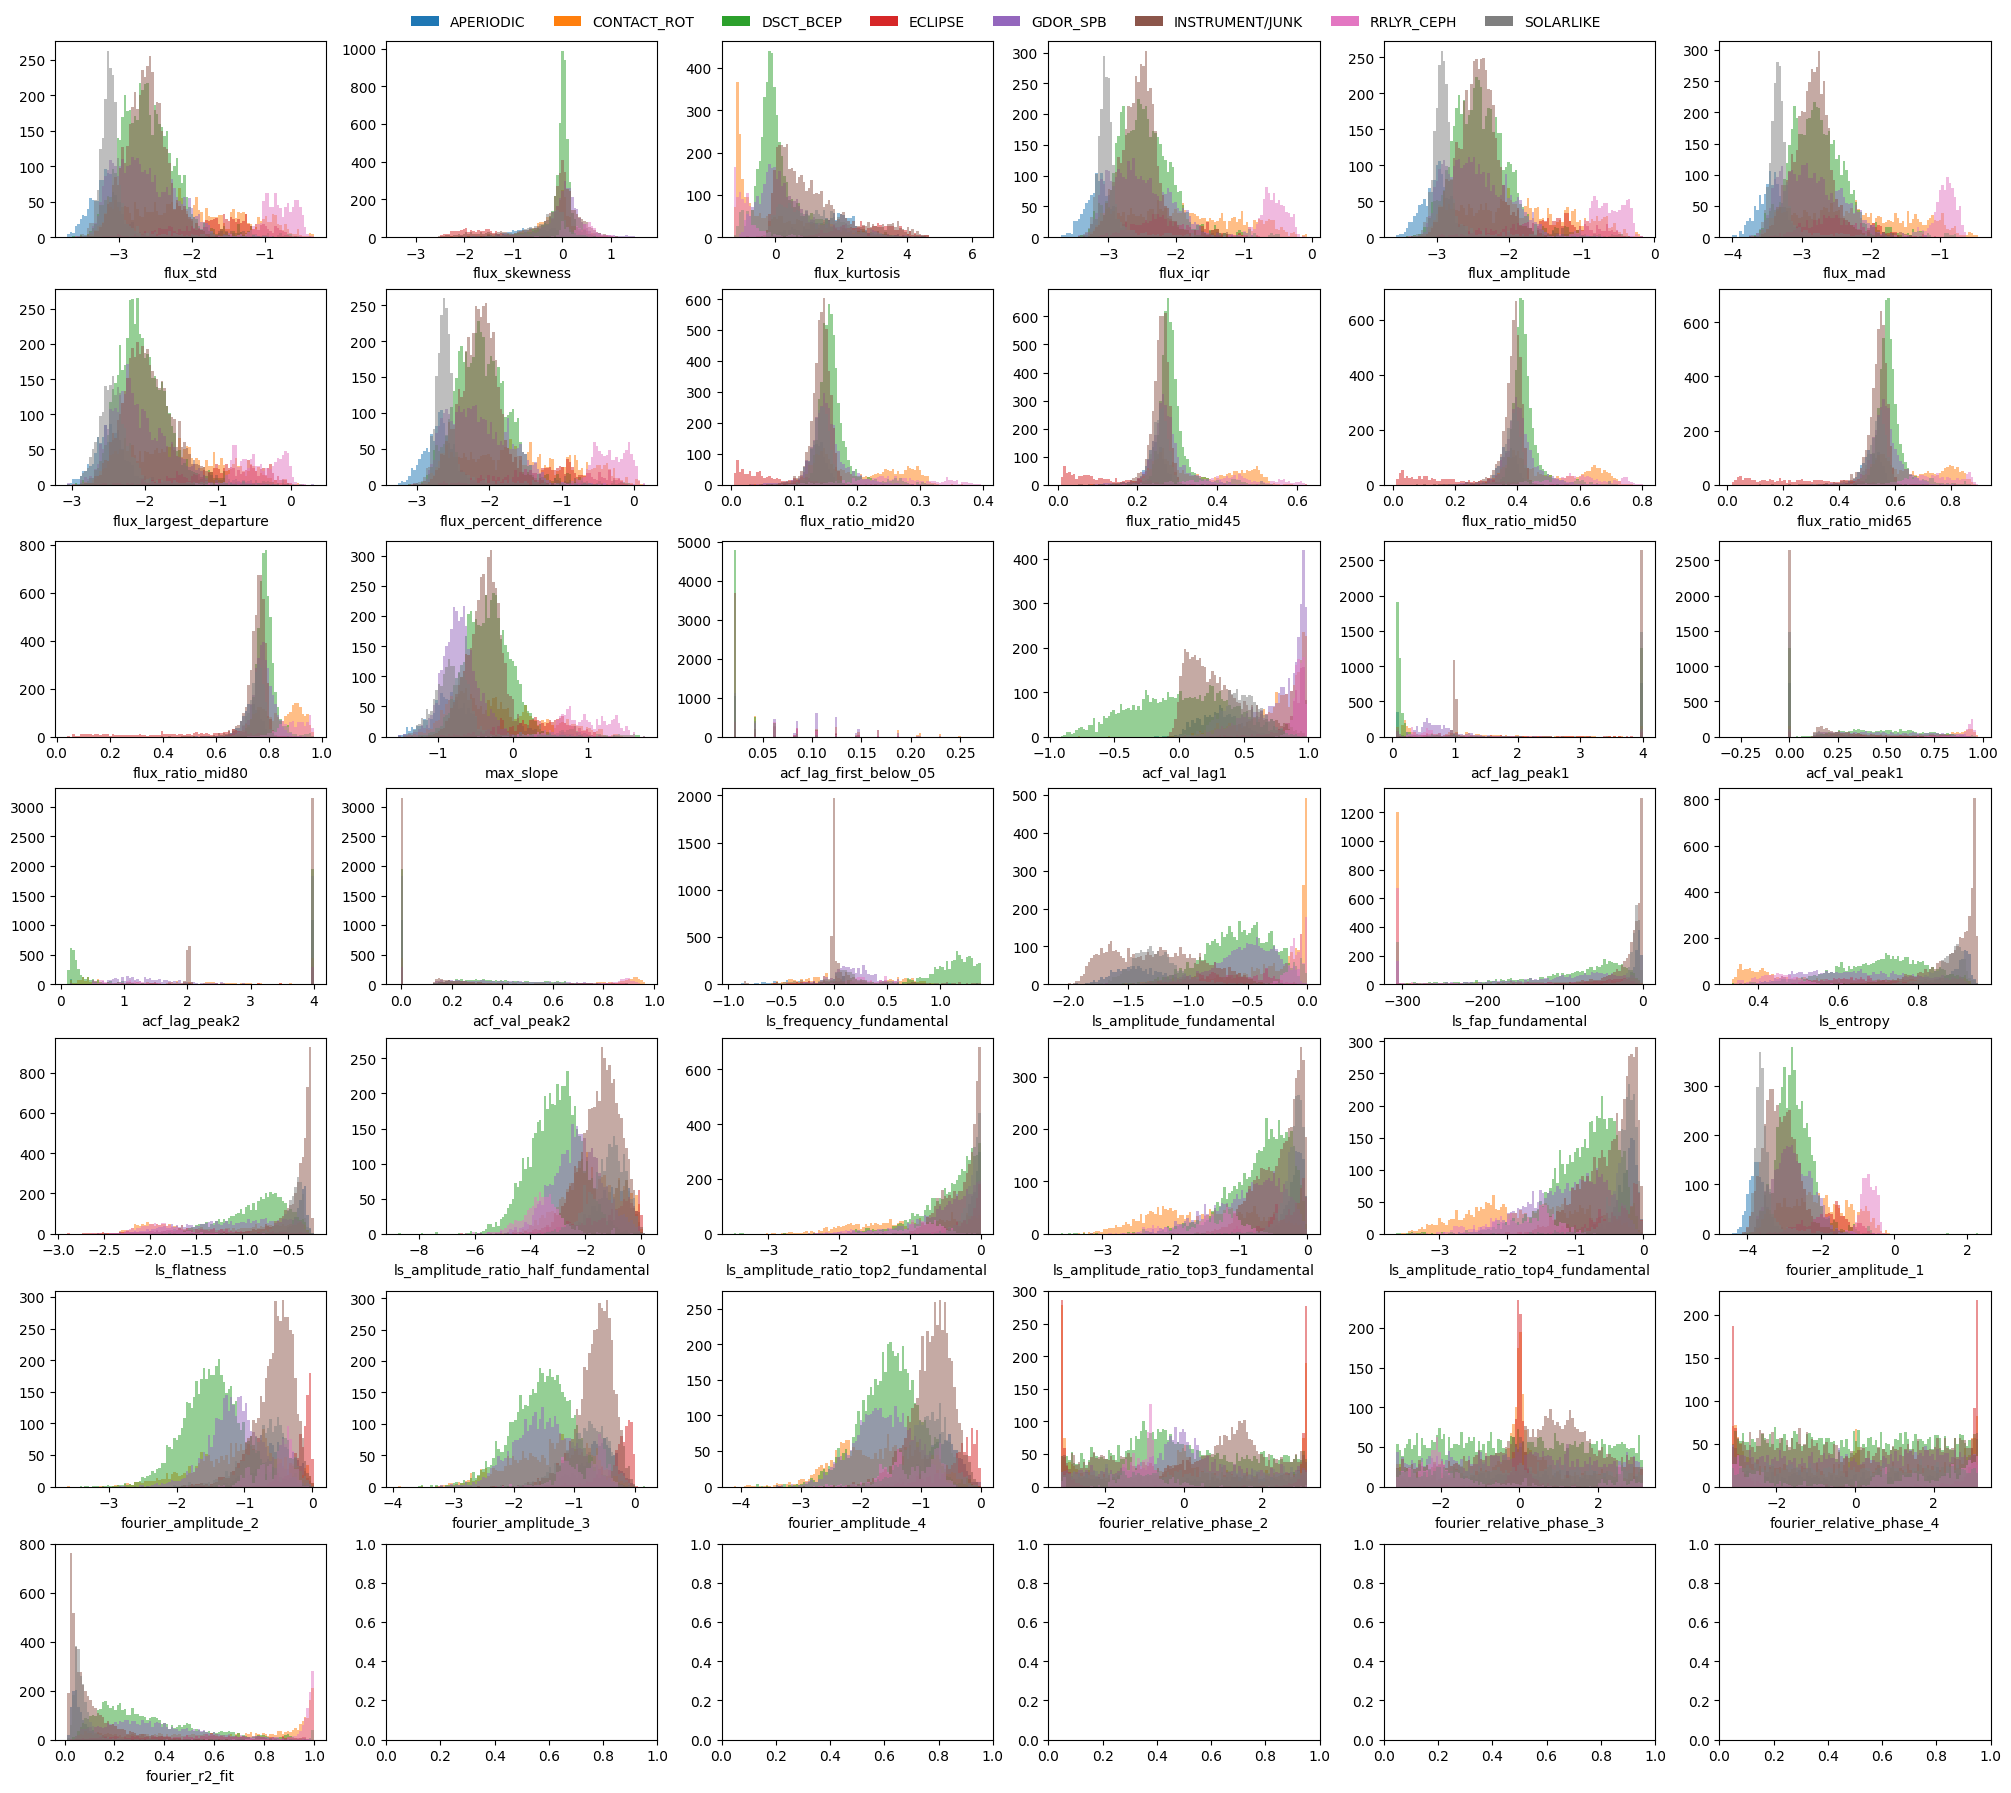

In [12]:
# Visualizing the features
bins = 100
n_rows = 7
fig, axs = plt.subplots(n_rows, 6, figsize=(20, 2.5*n_rows), constrained_layout=True)
for ax, col, col_name in zip(axs.ravel(), X_fit.T, X_names):
    hrange = (np.amin(col), np.amax(col))
    for name in y_names:
        mask = y_fit == name
        ax.hist(col[mask], range=hrange, bins=bins, label=name, alpha=0.5)
    ax.set_xlabel(col_name)

handles, labels = axs.ravel()[0].get_legend_handles_labels()
leg = fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02), frameon=False)
for h in leg.legend_handles:
    h.set_alpha(1.0)

## Feature relevance/redundancy

In [11]:
%%time
from sklearn.feature_selection import mutual_info_classif

MI = mutual_info_classif(X_fit, y_fit, n_neighbors=3, copy=True, random_state=1234, n_jobs=16)

CPU times: user 219 ms, sys: 37.3 ms, total: 256 ms
Wall time: 3.14 s


In [13]:
sort_mi = np.argsort(MI)[::-1]
for name, mi_ in zip(X_names[sort_mi], MI[sort_mi]):
    print(f"{mi_:0.4f} : {name:40}")

0.9849 : ls_frequency_fundamental                
0.8533 : acf_lag_peak1                           
0.7583 : acf_lag_peak2                           
0.6059 : acf_lag_first_below_05                  
0.5941 : acf_val_lag1                            
0.5754 : fourier_r2_fit                          
0.5705 : ls_amplitude_fundamental                
0.5467 : ls_entropy                              
0.5348 : ls_fap_fundamental                      
0.5176 : ls_flatness                             
0.5113 : fourier_amplitude_1                     
0.4544 : flux_iqr                                
0.4542 : flux_mad                                
0.4519 : flux_amplitude                          
0.4508 : flux_percent_difference                 
0.4467 : flux_std                                
0.4293 : flux_ratio_mid65                        
0.4273 : flux_ratio_mid50                        
0.4256 : flux_ratio_mid45                        
0.4166 : flux_ratio_mid80                        


# Classifiers

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

le = LabelEncoder().fit(y_fit)

with open(save_path / 'label_encoder.pkl', "wb") as f:
    dump(le, f, protocol=5)

## K-nn

In [30]:
# k-nn classifier, macro f1 record: 0.844

pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('classifier', KNeighborsClassifier(n_jobs=1))
])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)
param_grid={'classifier__n_neighbors': [15, 25], 'classifier__weights': ['uniform', 'distance']}

clf = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring='f1_macro', n_jobs=4)
clf.fit(X_fit, le.transform(y_fit), groups=groups_fit)

print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test)), digits=3))

                 precision    recall  f1-score   support

      APERIODIC      0.761     0.662     0.708       317
    CONTACT_ROT      0.948     0.648     0.770       708
      DSCT_BCEP      0.932     0.951     0.941      1233
        ECLIPSE      0.971     0.839     0.900       242
       GDOR_SPB      0.793     0.840     0.816       843
INSTRUMENT/JUNK      0.844     0.932     0.886      1075
     RRLYR_CEPH      0.968     0.977     0.972       214
      SOLARLIKE      0.692     0.834     0.756       529

       accuracy                          0.854      5161
      macro avg      0.864     0.835     0.844      5161
   weighted avg      0.861     0.854     0.852      5161



In [33]:
# Best hyperparameters 
pl.DataFrame(clf.cv_results_).sort('rank_test_score').drop(['^.*_time$', 'params'])

param_classifier__n_neighbors,param_classifier__weights,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
i64,str,f64,f64,f64,f64,f64,f64,f64,i32
15,"""uniform""",0.835335,0.825612,0.818981,0.830117,0.833535,0.828716,0.005889,1
15,"""distance""",0.832884,0.824051,0.818908,0.830841,0.834247,0.828186,0.005814,2
25,"""distance""",0.830993,0.82617,0.813896,0.827856,0.83713,0.827209,0.007635,3
25,"""uniform""",0.830449,0.826523,0.811473,0.827787,0.836275,0.826501,0.008229,4


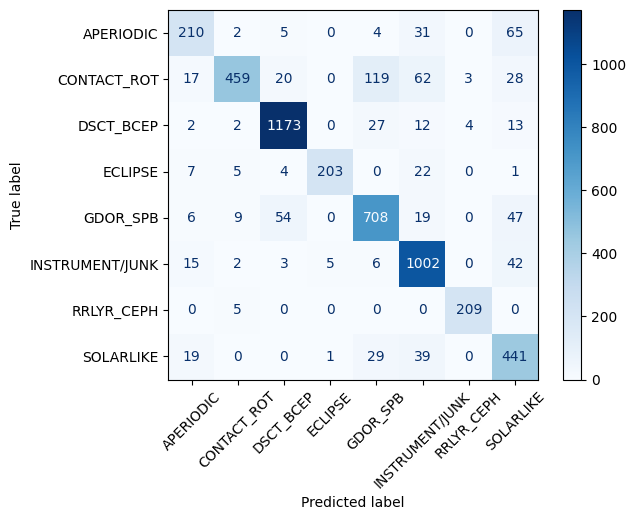

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

y_test_pred = le.inverse_transform(clf.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45)

## Random Forest

In [97]:
%%time

# Random Forest, macro f1 record: 0.904

pipeline = Pipeline([
    #('scaler', RobustScaler()), 
    ('classifier', RandomForestClassifier(n_jobs=32, random_state=1234, class_weight='balanced'))
])

param_grid={
    "classifier__n_estimators": [300, 600],
    "classifier__max_depth": [10, 20],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__max_features": [int(np.sqrt(X_fit.shape[1])), 0.3, 0.6], # sqrt is default
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)
clf = GridSearchCV(estimator=pipeline, param_grid=param_grid, n_jobs=1, cv=cv, scoring='f1_macro', verbose=1)

clf.fit(X_fit, le.transform(y_fit), groups=groups_fit)
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test)), digits=3))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
                 precision    recall  f1-score   support

      APERIODIC      0.772     0.789     0.780       317
    CONTACT_ROT      0.910     0.838     0.872       708
      DSCT_BCEP      0.983     0.978     0.980      1233
        ECLIPSE      0.987     0.917     0.951       242
       GDOR_SPB      0.908     0.921     0.914       843
INSTRUMENT/JUNK      0.912     0.956     0.934      1075
     RRLYR_CEPH      0.990     0.953     0.971       214
      SOLARLIKE      0.820     0.845     0.832       529

       accuracy                          0.916      5161
      macro avg      0.910     0.900     0.904      5161
   weighted avg      0.917     0.916     0.916      5161

CPU times: user 5h 20min 24s, sys: 26.3 s, total: 5h 20min 51s
Wall time: 11min 38s


In [98]:
# Best hyperparameters
pl.DataFrame(clf.cv_results_, strict=False).sort('rank_test_score').drop(['^.*_time$', 'params']).head(10)

param_classifier__max_depth,param_classifier__max_features,param_classifier__min_samples_leaf,param_classifier__n_estimators,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
i64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,i32
20,0.3,1,300,0.899072,0.873464,0.891736,0.887516,0.883481,0.887054,0.008532,1
20,0.6,1,300,0.899577,0.868001,0.892192,0.892231,0.881041,0.886609,0.011029,2
20,0.6,2,600,0.898236,0.871745,0.892172,0.891596,0.879136,0.886577,0.009672,3
20,0.3,1,600,0.899084,0.872155,0.88995,0.88751,0.883745,0.886489,0.008771,4
20,0.6,1,600,0.897656,0.868148,0.891306,0.891515,0.881978,0.88612,0.010288,5
20,0.6,2,300,0.897983,0.870956,0.8917,0.891147,0.878415,0.88604,0.009863,6
20,0.3,2,300,0.897643,0.872846,0.892702,0.884856,0.880069,0.885623,0.008824,7
20,0.3,2,600,0.897047,0.871834,0.892451,0.885686,0.8807,0.885544,0.008848,8
20,6.0,2,300,0.898242,0.871049,0.890844,0.884105,0.878711,0.88459,0.00942,9


Text(0.5, 1.0, 'Full dataset')

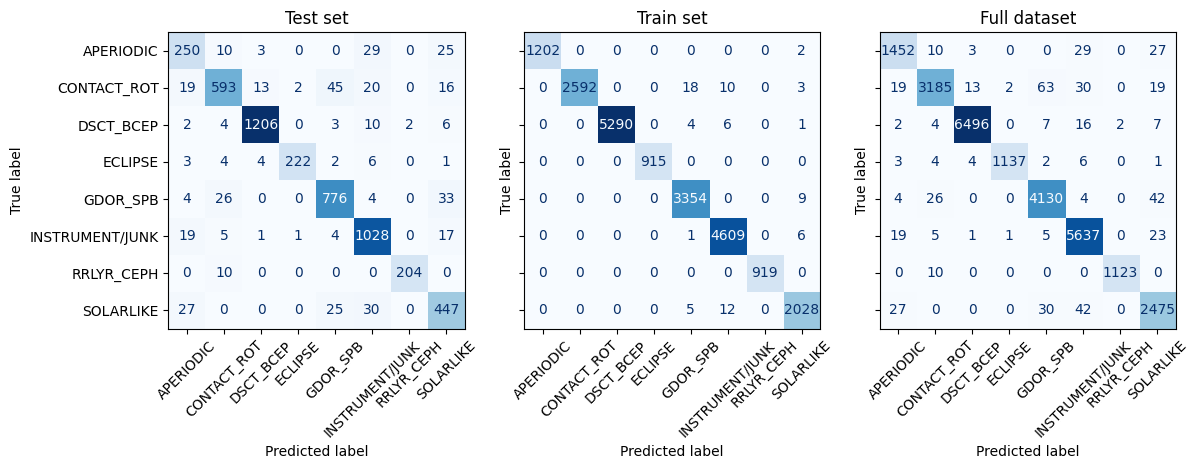

In [99]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(clf.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False)
axs[0].set_title('Test set')
y_fit_pred = le.inverse_transform(clf.predict(X_fit))
ConfusionMatrixDisplay.from_predictions(y_true=y_fit, y_pred=y_fit_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False)
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_fit, y_test]), y_pred=np.concatenate([y_fit_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False)
axs[2].set_title('Full dataset')

Text(0.5, 1.0, 'Random Forest Mean Decrease in Impurity')

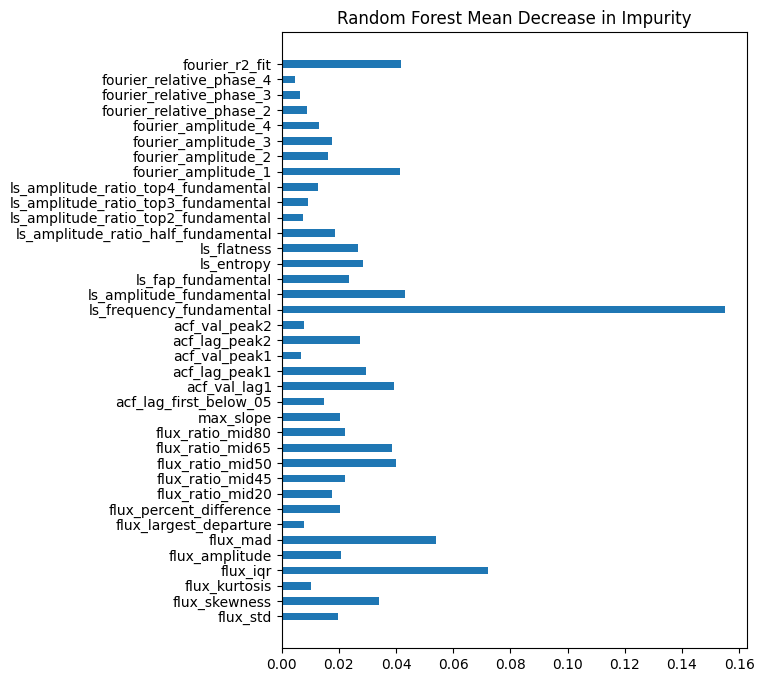

In [100]:
fig, ax = plt.subplots(figsize=(6, 8))

#RF MDI has a few drabacks
# Biased toward high-cardinality or continuous features (i.e. features with many possible split points are favored)
# Inflated importance for correlated predictors.
# It is a training-set measure. It does not evaluate generalization impact.

ax.barh(X_names, clf.best_estimator_['classifier'].feature_importances_, height=0.5)
ax.set_title('Random Forest Mean Decrease in Impurity')

## XGBOOST

In [16]:
%%time

from sklearn.model_selection import RandomizedSearchCV

# XGBoost, macro f1 record: 0.918

pipeline = Pipeline([
    #('scaler', RobustScaler()), # XGBoost does not benefit from scaling
    ('classifier',  XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist", n_jobs=8, random_state=1234))
])

param_grid = { # A conservative grid to avoid memorization of training set
    "classifier__n_estimators": [200, 400, 800],
    "classifier__max_depth": [2, 3, 4], # default 6 
    "classifier__min_child_weight": [10, 20, 40], # default 1
    "classifier__gamma": [0, 0.5, 1.0, 2.0],
    "classifier__reg_lambda": [2.0, 5.0, 10.0], # default 1.0
    "classifier__reg_alpha": [0.0, 0.1, 1.0], # default 0.0
    "classifier__learning_rate": [0.02, 0.05, 0.1], # default 0.3
    "classifier__colsample_bytree": [0.6, 0.8], # default 1.0
    "classifier__subsample": [0.6, 0.8], #default 1.0
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)
clf = RandomizedSearchCV(estimator=pipeline, param_distributions=param_grid, scoring="f1_macro", cv=cv, n_jobs=4, verbose=1, n_iter=100)
clf.fit(X_fit, le.transform(y_fit), groups=groups_fit)
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test)), digits=3))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
                 precision    recall  f1-score   support

      APERIODIC      0.848     0.795     0.821       317
    CONTACT_ROT      0.922     0.849     0.884       708
      DSCT_BCEP      0.971     0.979     0.975      1233
        ECLIPSE      0.974     0.946     0.960       242
       GDOR_SPB      0.900     0.923     0.912       843
INSTRUMENT/JUNK      0.936     0.956     0.946      1075
     RRLYR_CEPH      0.981     0.972     0.977       214
      SOLARLIKE      0.834     0.883     0.858       529

       accuracy                          0.924      5161
      macro avg      0.921     0.913     0.916      5161
   weighted avg      0.925     0.924     0.924      5161

CPU times: user 1min 3s, sys: 523 ms, total: 1min 3s
Wall time: 8min 9s


In [21]:
# Best hyperparameters
pl.DataFrame(clf.cv_results_, strict=False).sort('rank_test_score').drop(['^.*_time$', 'params']).head(10)

param_classifier__subsample,param_classifier__reg_lambda,param_classifier__reg_alpha,param_classifier__n_estimators,param_classifier__min_child_weight,param_classifier__max_depth,param_classifier__learning_rate,param_classifier__gamma,param_classifier__colsample_bytree,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
f64,f64,f64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
0.6,10.0,0.1,800,20,4,0.1,0.0,0.6,0.91384,0.898748,0.908487,0.903394,0.895204,0.903935,0.006667,1
0.8,5.0,0.0,800,10,3,0.05,0.0,0.6,0.916858,0.895751,0.907725,0.900041,0.899128,0.903901,0.007571,2
0.8,10.0,1.0,400,40,4,0.1,0.0,0.6,0.919159,0.89882,0.907178,0.901043,0.892741,0.903788,0.008967,3
0.8,10.0,1.0,400,20,4,0.1,0.0,0.6,0.915357,0.897567,0.905291,0.903498,0.894999,0.903343,0.007087,4
0.8,2.0,1.0,800,10,3,0.05,1.0,0.6,0.918793,0.894915,0.904165,0.900413,0.897136,0.903084,0.008452,5
0.8,2.0,0.1,800,40,3,0.1,0.0,0.8,0.913391,0.89803,0.90739,0.901232,0.895003,0.903009,0.006618,6
0.6,10.0,1.0,800,10,4,0.05,0.0,0.8,0.916206,0.898341,0.904789,0.898882,0.895933,0.90283,0.007294,7
0.6,2.0,1.0,400,10,4,0.05,0.5,0.6,0.917149,0.896461,0.904077,0.900839,0.895602,0.902826,0.007789,8
0.8,10.0,0.1,800,10,3,0.05,0.0,0.8,0.918082,0.893388,0.905567,0.900754,0.895036,0.902565,0.008876,9


In [108]:
clf.best_estimator_.get_params()

{'memory': None,
 'steps': [('classifier',
   XGBClassifier(base_score=None, booster=None, callbacks=None,
                 colsample_bylevel=None, colsample_bynode=None,
                 colsample_bytree=0.6, device=None, early_stopping_rounds=None,
                 enable_categorical=False, eval_metric='mlogloss',
                 feature_types=None, feature_weights=None, gamma=0,
                 grow_policy=None, importance_type=None,
                 interaction_constraints=None, learning_rate=0.1, max_bin=None,
                 max_cat_threshold=None, max_cat_to_onehot=None,
                 max_delta_step=None, max_depth=4, max_leaves=None,
                 min_child_weight=20, missing=nan, monotone_constraints=None,
                 multi_strategy=None, n_estimators=800, n_jobs=8,
                 num_parallel_tree=None, ...))],
 'transform_input': None,
 'verbose': False,
 'classifier': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylev

Text(0.5, 1.0, 'Full dataset')

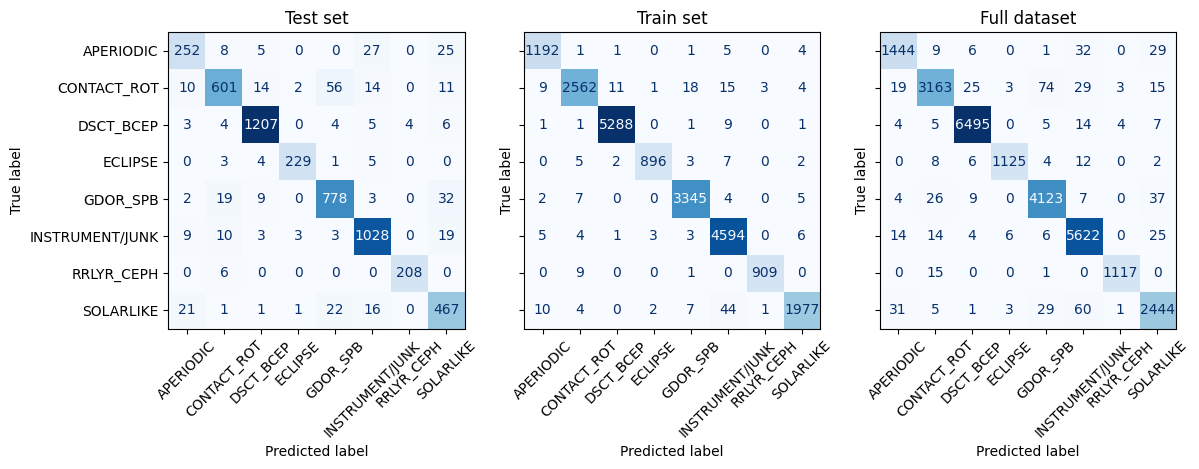

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(clf.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False)
axs[0].set_title('Test set')
y_fit_pred = le.inverse_transform(clf.predict(X_fit))
ConfusionMatrixDisplay.from_predictions(y_true=y_fit, y_pred=y_fit_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False)
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_fit, y_test]), y_pred=np.concatenate([y_fit_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False)
axs[2].set_title('Full dataset')

Text(0.5, 1.0, 'Full dataset')

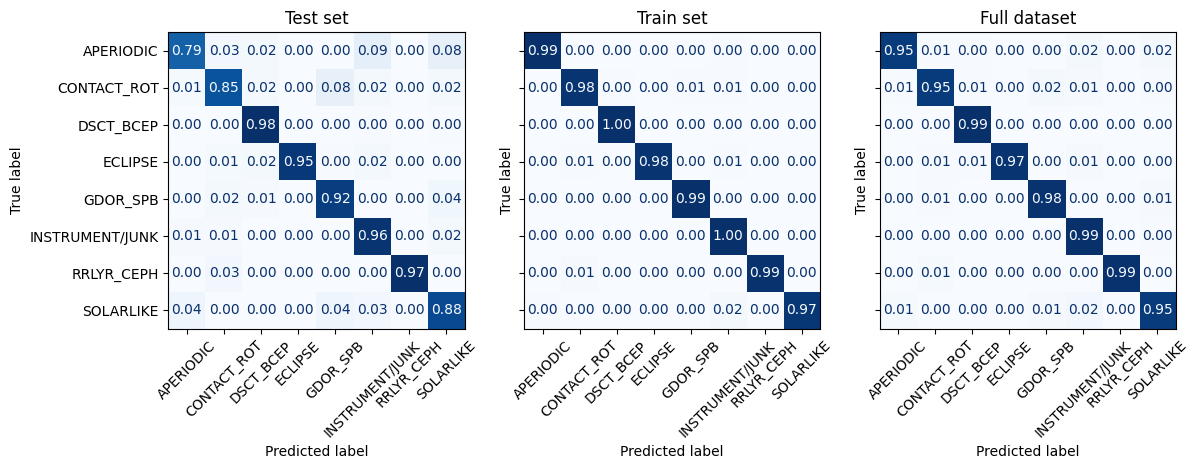

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(clf.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False, normalize='true', values_format='0.2f')
axs[0].set_title('Test set')
y_fit_pred = le.inverse_transform(clf.predict(X_fit))
ConfusionMatrixDisplay.from_predictions(y_true=y_fit, y_pred=y_fit_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False, normalize='true', values_format='0.2f')
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_fit, y_test]), y_pred=np.concatenate([y_fit_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False, normalize='true', values_format='0.2f')
axs[2].set_title('Full dataset')

CPU times: user 6.29 s, sys: 160 ms, total: 6.45 s
Wall time: 20.1 s


Text(0.5, 1.0, 'Permutation-based feature importance')

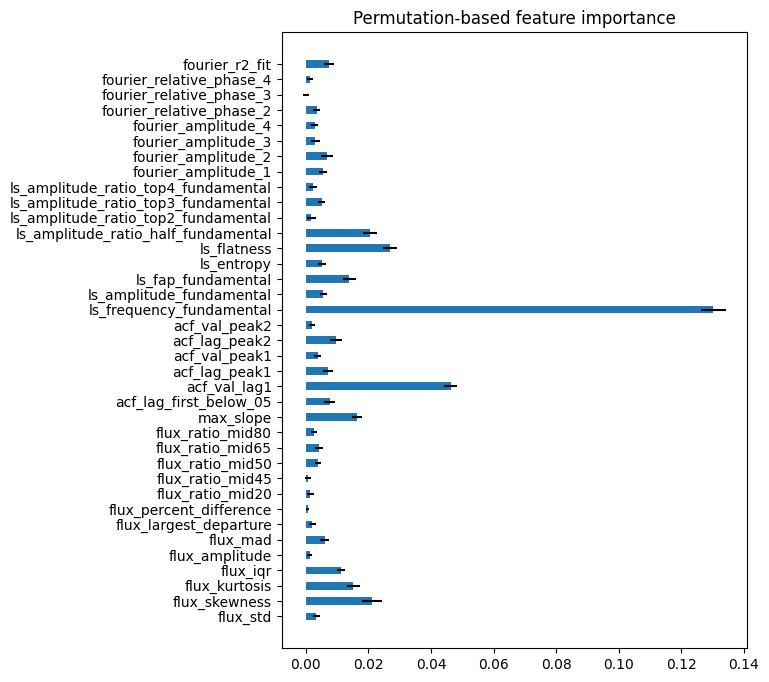

In [24]:
%%time
from sklearn.inspection import permutation_importance

# Permutation importance drawbacks:
# Underestimates importance under feature correlation.
# If two features encode the same information, permuting one may not hurt performance.

pi_global = permutation_importance(clf.best_estimator_, X_test, le.transform(y_test), scoring="f1_macro", n_repeats=30, random_state=0, n_jobs=16)

fig, ax = plt.subplots(figsize=(6, 8))
ax.barh(y=np.array(X_names), width=pi_global.importances_mean, xerr=pi_global.importances_std, height=0.5)
ax.set_title('Permutation-based feature importance')

CPU times: user 6.46 s, sys: 133 ms, total: 6.59 s
Wall time: 21.6 s


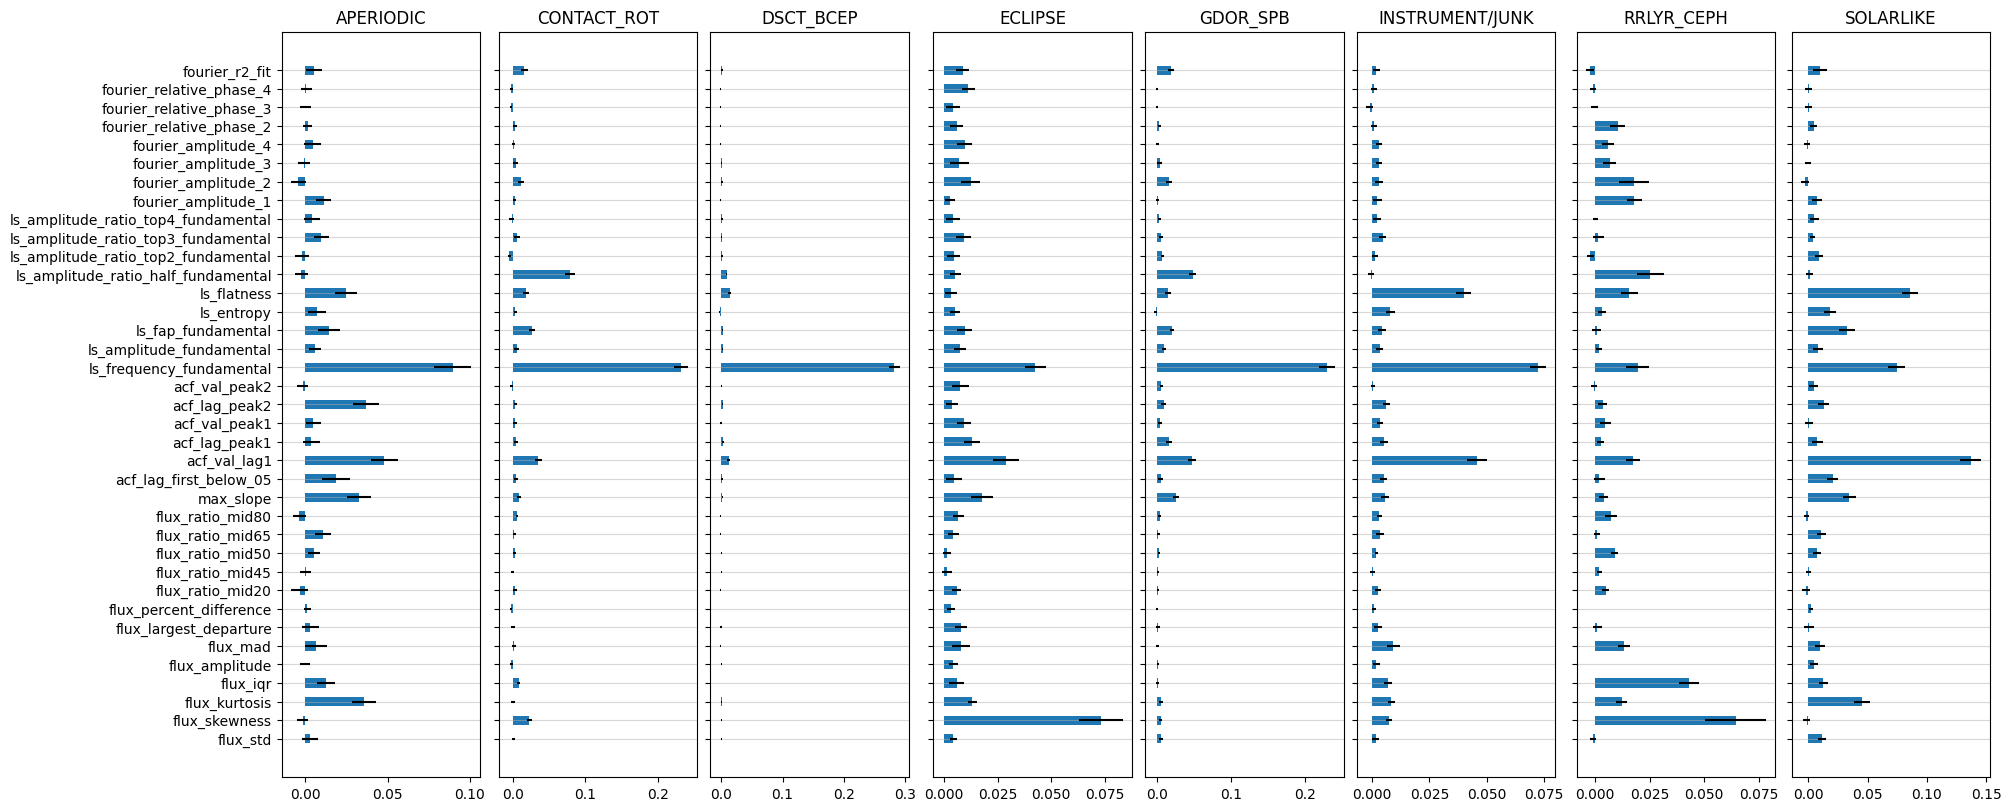

In [25]:
%%time
from sklearn.metrics import f1_score

best_clf = clf.best_estimator_
classes = np.unique(le.transform(y_test))

def per_class_f1_scorer(estimator, X, y):
    y_pred = estimator.predict(X)
    return np.array([f1_score(y == c, y_pred == c, zero_division=0) for c in classes], dtype=float)

pi_class = permutation_importance(best_clf, X_test, le.transform(y_test), scoring=per_class_f1_scorer, n_repeats=30, random_state=0, n_jobs=16)

fig, axs = plt.subplots(1, len(classes), figsize=(20, 8), sharey=True, constrained_layout=True)
for ax, name, pi_class_mean, pi_class_std in zip(axs, classes, pi_class.importances_mean.T, pi_class.importances_std.T):
    ax.barh(y=np.array(X_names), width=pi_class_mean, xerr=pi_class_std, height=0.5)
    ax.set_title(le.inverse_transform([name]).item())
    ax.grid(axis='y', alpha=0.5)

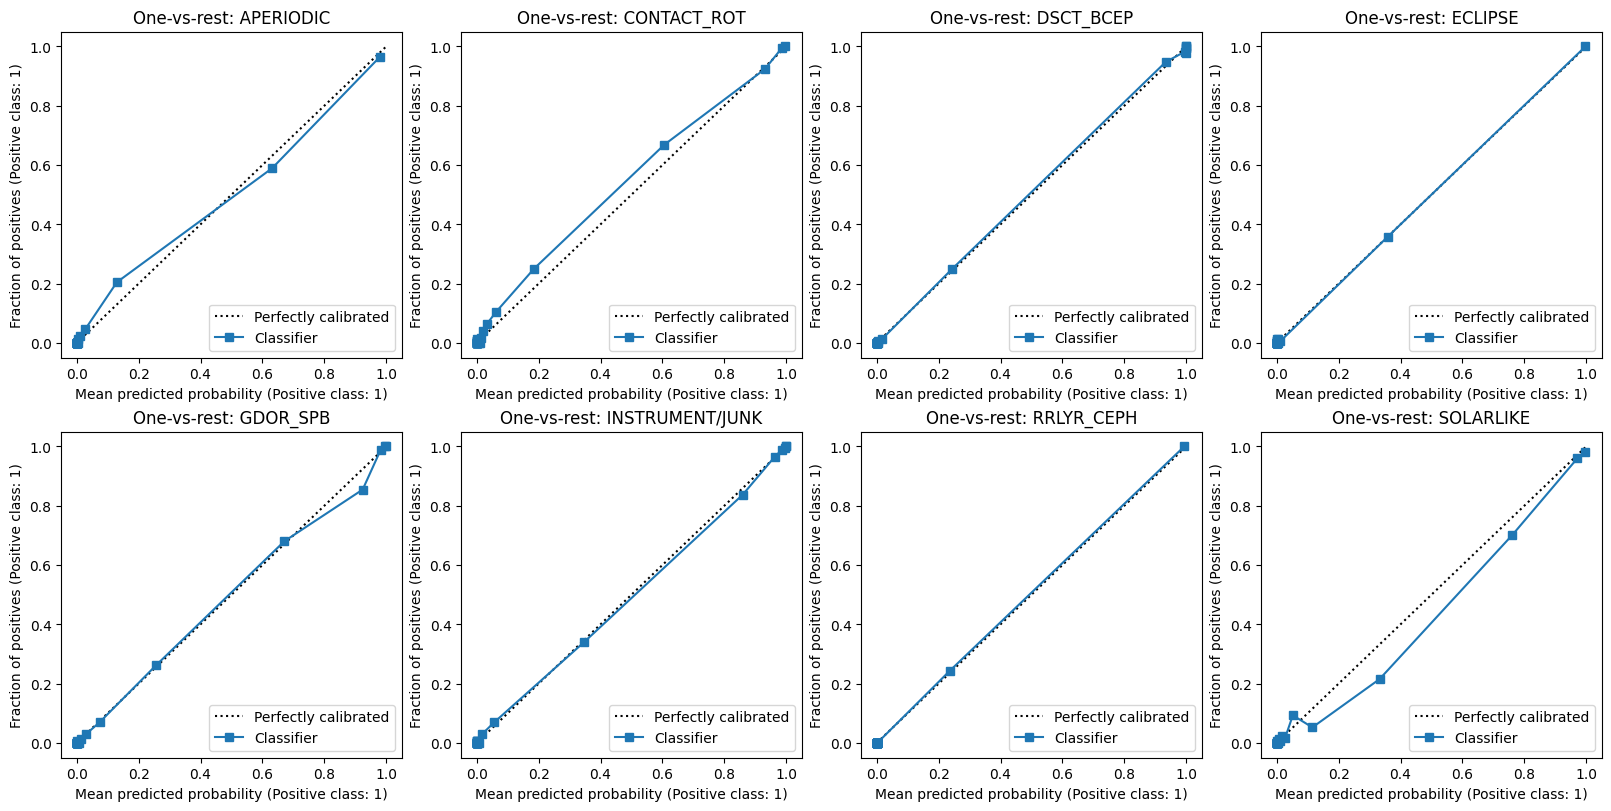

In [33]:
# How good is the calibration of the model?

from sklearn.calibration import CalibrationDisplay

est = clf.best_estimator_
proba = est.predict_proba(X_test)
classes = est.classes_
fig, axs = plt.subplots(2, len(classes)//2, figsize=(16, 8), sharey=False, constrained_layout=True)

for ax, c in zip(np.atleast_1d(axs.ravel()), classes):
    k = np.where(classes == c)[0][0]
    y_bin = (le.transform(y_test) == c).astype(int)
    p_c = proba[:, k]
    CalibrationDisplay.from_predictions(y_true=y_bin, y_prob=p_c, n_bins=30, strategy="quantile", ax=ax)
    ax.set_title(f"One-vs-rest: {le.inverse_transform(np.array([c]))[0]}")

## XGBoost with feature selector

In [66]:
%%time

from sklearn.feature_selection import RFE

ranker = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.1, subsample=0.75, colsample_bytree=0.8, reg_lambda=1.0, 
    tree_method="hist", n_jobs=8, random_state=1234, eval_metric="logloss")


pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('selector', RFE(estimator=ranker, step=2)),
    ('classifier',  XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist", n_jobs=8, random_state=1234))
])

param_grid = {
    "classifier__n_estimators": [300], 
    "classifier__max_depth": [5],
    "classifier__min_child_weight": [5],
    "classifier__gamma": [0.5],
    "classifier__learning_rate": [0.1],
    "classifier__colsample_bytree": [0.8],
    "classifier__subsample": [0.75],
    "selector__n_features_to_select": [8, 12, 18, 25, 37],
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)
clf_fs = GridSearchCV(estimator=pipeline, param_grid=param_grid, scoring="f1_macro", cv=cv, n_jobs=4, verbose=1)
clf_fs.fit(X_fit, le.transform(y_fit), groups=groups_fit)
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test)), digits=3))

Fitting 5 folds for each of 5 candidates, totalling 25 fits
                 precision    recall  f1-score   support

      APERIODIC      0.836     0.804     0.820       317
    CONTACT_ROT      0.922     0.855     0.887       708
      DSCT_BCEP      0.973     0.981     0.977      1233
        ECLIPSE      0.983     0.946     0.964       242
       GDOR_SPB      0.910     0.925     0.918       843
INSTRUMENT/JUNK      0.930     0.959     0.944      1075
     RRLYR_CEPH      0.977     0.981     0.979       214
      SOLARLIKE      0.847     0.870     0.858       529

       accuracy                          0.926      5161
      macro avg      0.922     0.915     0.918      5161
   weighted avg      0.926     0.926     0.926      5161

CPU times: user 50.8 s, sys: 337 ms, total: 51.1 s
Wall time: 2min 50s


In [67]:
# Best hyperparameters
pl.DataFrame(clf_fs.cv_results_, strict=False).sort('rank_test_score').drop(['^.*_time$', 'params']).head(10)

param_classifier__colsample_bytree,param_classifier__gamma,param_classifier__learning_rate,param_classifier__max_depth,param_classifier__min_child_weight,param_classifier__n_estimators,param_classifier__subsample,param_selector__n_features_to_select,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
f64,f64,f64,i64,i64,i64,f64,i64,f64,f64,f64,f64,f64,f64,f64,i32
0.8,0.5,0.1,5,5,300,0.75,37,0.918522,0.901998,0.90923,0.90128,0.897633,0.905733,0.007418,1
0.8,0.5,0.1,5,5,300,0.75,25,0.917786,0.899614,0.901046,0.899399,0.896629,0.902895,0.007582,2
0.8,0.5,0.1,5,5,300,0.75,18,0.9084,0.881968,0.876682,0.8971,0.893519,0.891534,0.011238,3
0.8,0.5,0.1,5,5,300,0.75,12,0.893888,0.867018,0.865314,0.873816,0.874543,0.874916,0.010157,4
0.8,0.5,0.1,5,5,300,0.75,8,0.889124,0.852994,0.860044,0.84994,0.874685,0.865357,0.014633,5


Text(0.5, 1.0, 'Full dataset')

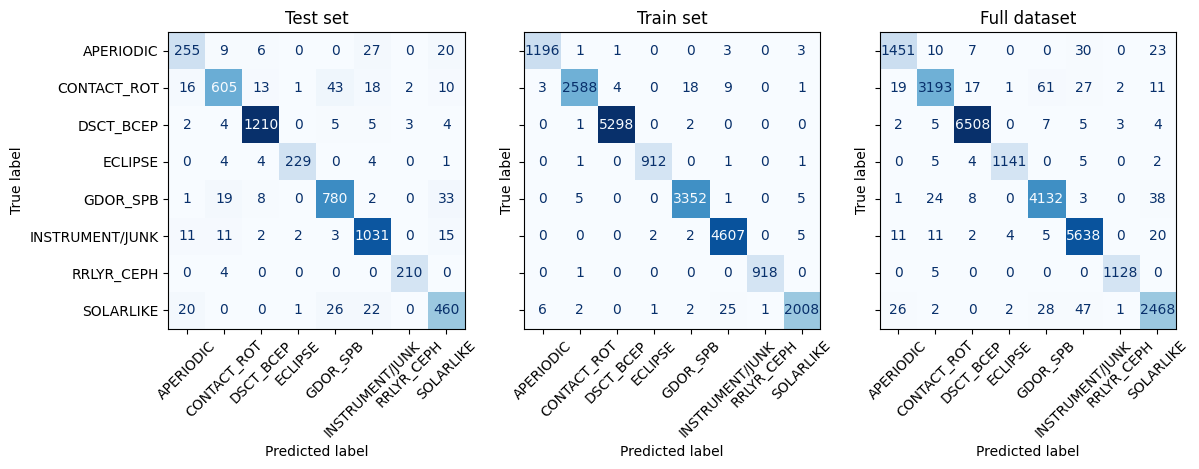

In [68]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(clf_fs.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False)
axs[0].set_title('Test set')
y_fit_pred = le.inverse_transform(clf_fs.predict(X_fit))
ConfusionMatrixDisplay.from_predictions(y_true=y_fit, y_pred=y_fit_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False)
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_fit, y_test]), y_pred=np.concatenate([y_fit_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False)
axs[2].set_title('Full dataset')

## Export best training set predictions and best classifier

In [35]:
paths_all = np.concatenate([path_fit, path_test])
y_all = np.concatenate([y_fit, y_test])
X_all = np.concatenate([X_fit, X_test], axis=0)

In [38]:
from training import prepare_predictions_dataframe

df_pred = prepare_predictions_dataframe(clf.best_estimator_, le, X=X_all, paths=paths_all, drop_nans=True)
display(df_pred.head())
#df_pred.write_parquet(save_path / 'predictions.parquet')

#with open(save_path / 'model_xgboost.pkl', "wb") as f:
#    dump(clf.best_estimator_, f, protocol=5)

path,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE,best_rf_class,rf_entropy,best_rf_proba
str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64
"""/STER/mamsie/tess/TIC/tglc_scr…",0.001005,0.008235,0.000165,0.000765,0.004979,0.980048,0.000077,0.004725,"""INSTRUMENT/JUNK""",0.06039,0.980048
"""/STER/mamsie/tess/TIC/tglc_scr…",0.003288,0.000462,0.000081,0.000066,0.001571,0.000404,0.000022,0.994106,"""SOLARLIKE""",0.020755,0.994106
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000666,0.009111,0.989117,0.000068,0.000707,0.000139,0.000033,0.00016,"""DSCT_BCEP""",0.03234,0.989117
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000103,0.979649,0.002309,0.00301,0.010149,0.002277,0.001521,0.000982,"""CONTACT_ROT""",0.062371,0.979649
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000892,0.006481,0.665303,0.005078,0.007117,0.30945,0.000136,0.005542,"""DSCT_BCEP""",0.367907,0.665303


## Visualization of feature space

CPU times: user 1min 52s, sys: 800 ms, total: 1min 52s
Wall time: 29.6 s


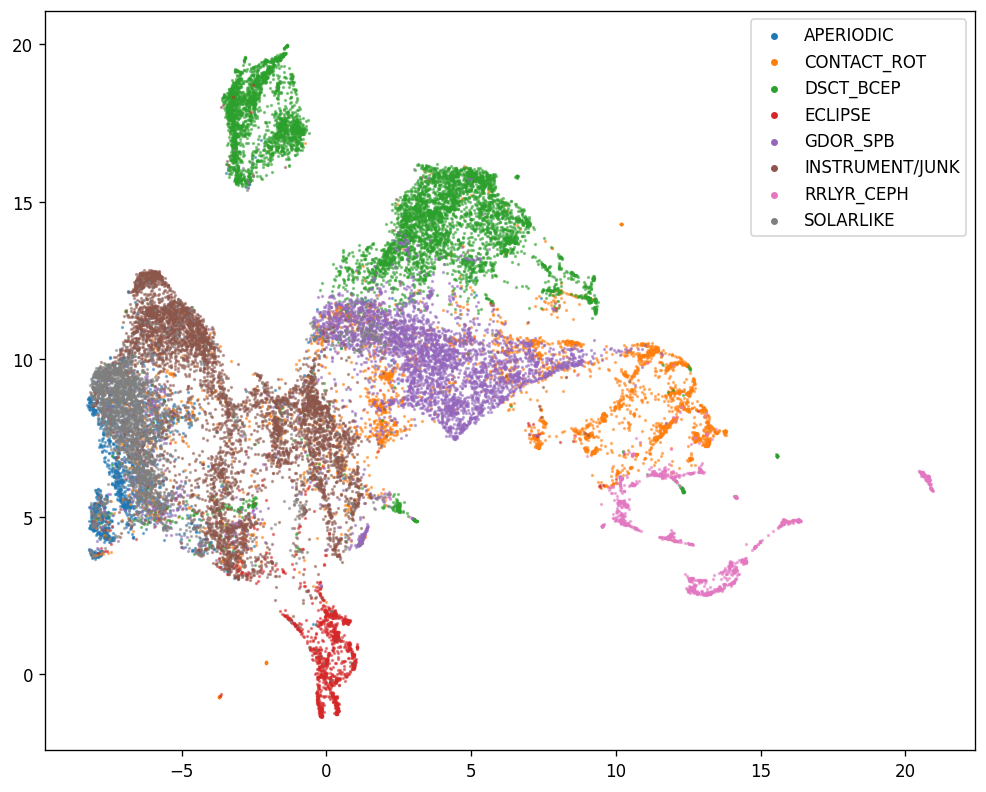

In [36]:
%%time
from umap import UMAP

pipeline_umap = Pipeline([
    ('scaler', RobustScaler()),
    ('projector',  UMAP(n_components=2, min_dist=0.1, negative_sample_rate=10, metric='euclidean', n_jobs=8, n_neighbors=25))
])

X_proj = pipeline_umap.fit_transform(X_all)
fig, ax = plt.subplots(figsize=(10, 8), dpi=120)

for name in y_names:
    mask = y_all == name
    ax.scatter(X_proj[mask, 0], X_proj[mask, 1], s=1, label=name, alpha=0.5)
leg = plt.legend()
for lh in leg.legend_handles:
    lh.set_alpha(1)
    lh._sizes = [10]

In [132]:
df_hv = pl.DataFrame({'lambda_1': X_proj[:, 0], 'lambda_2': X_proj[:, 1], 'class': y_all, 'path': paths_all})
df_hv = df_hv.join(df_training_features.select(['path', 'GaiaID', 'ls_frequency_fundamental']), on='path')
df_hv.write_parquet('viz.parquet')

## Error analysis

25
14


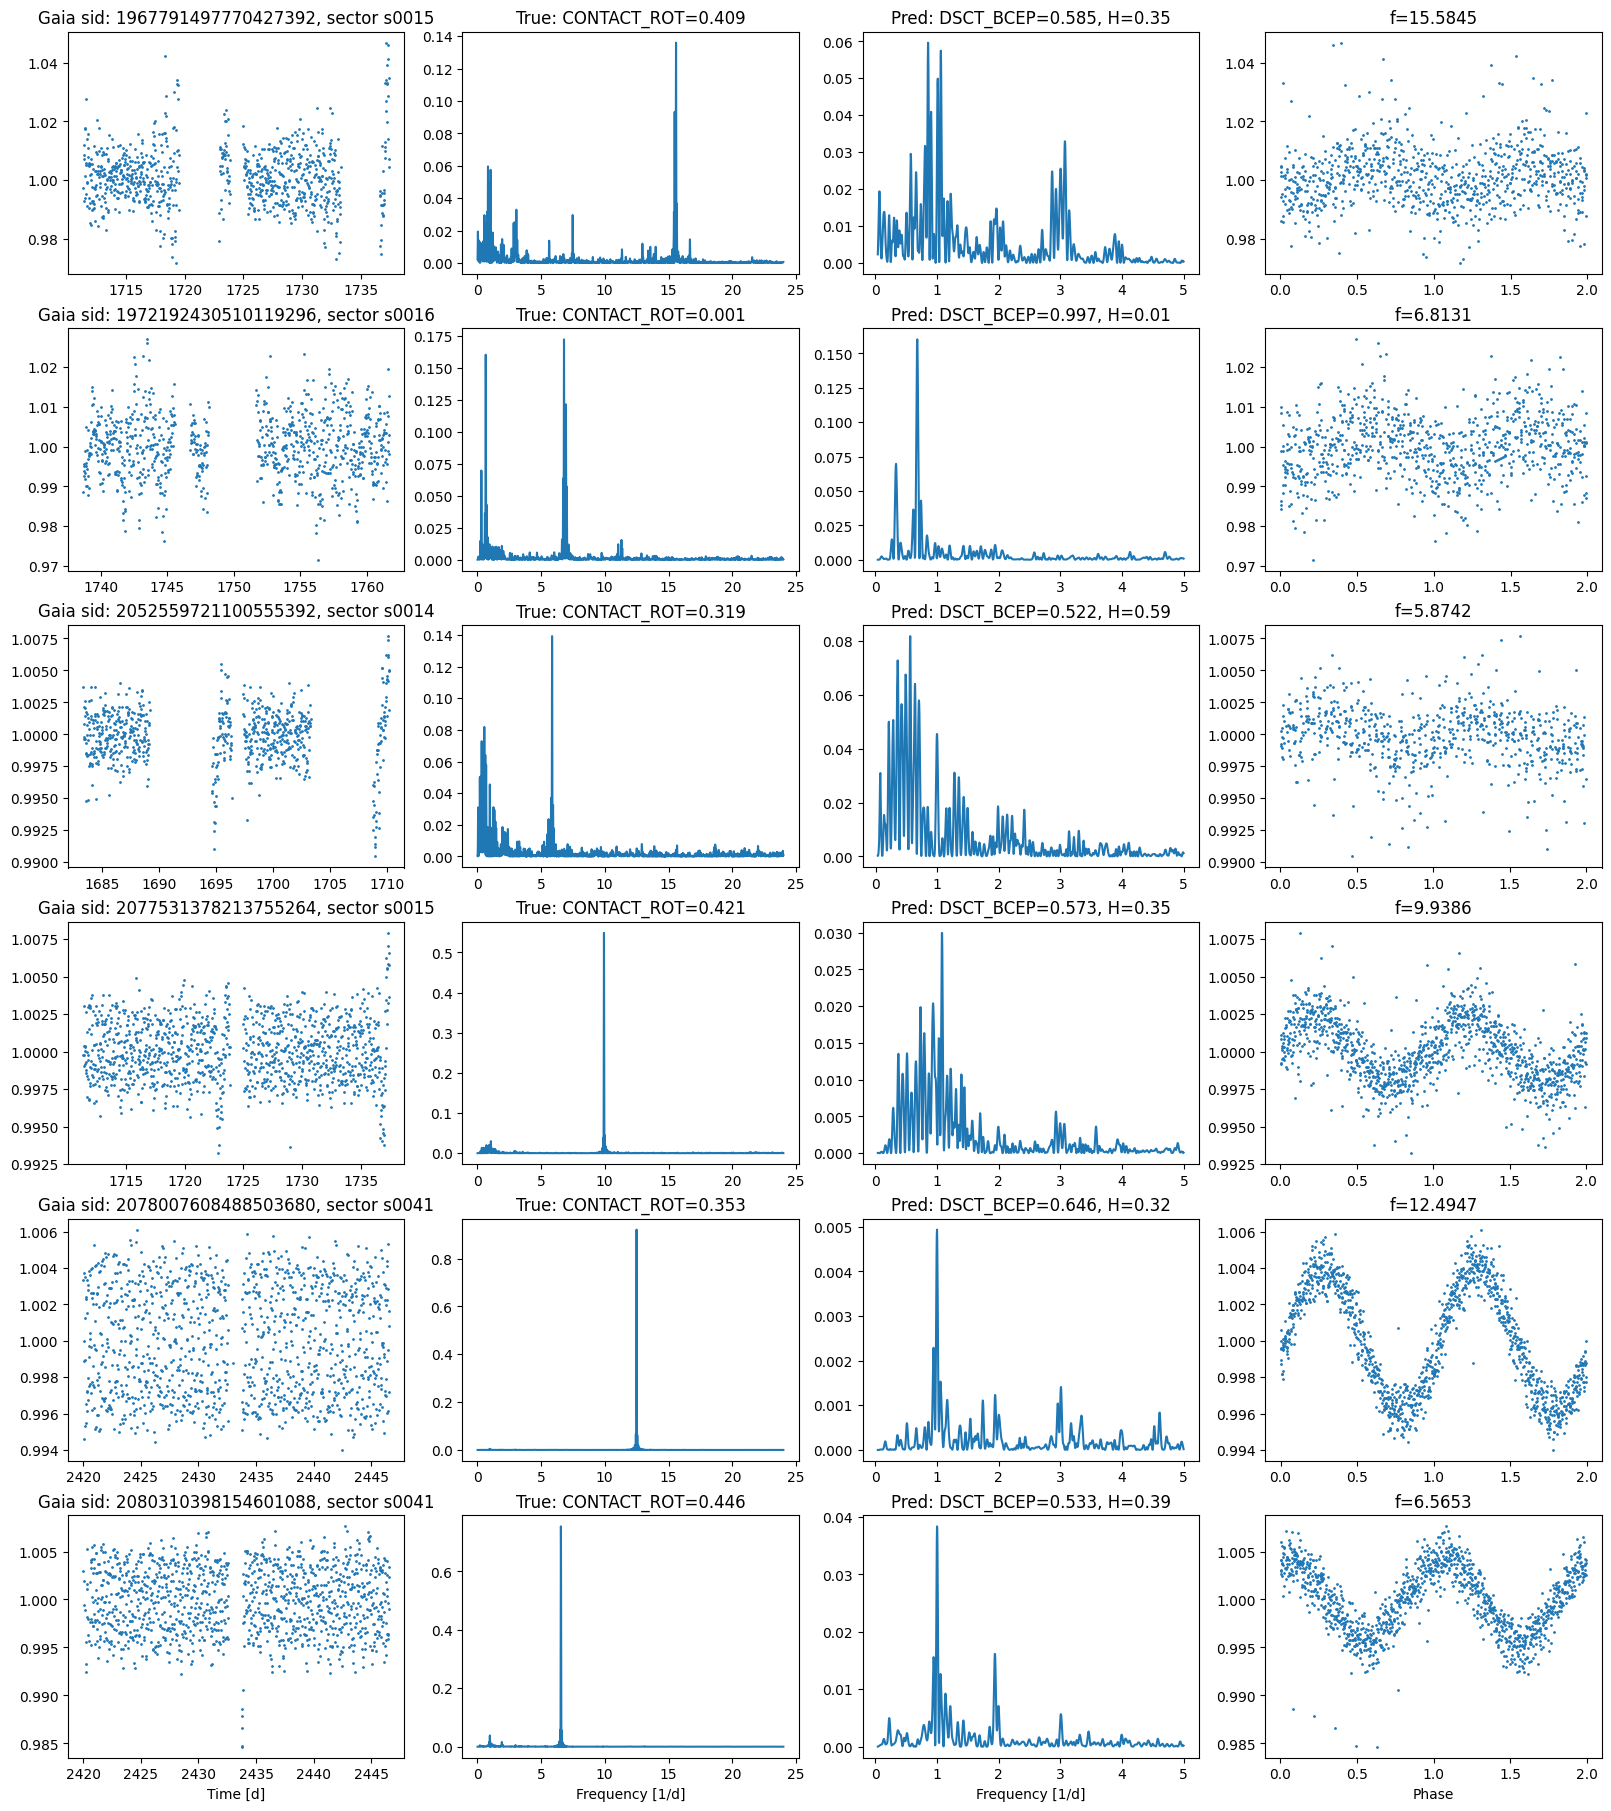

In [42]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from light_curves import read_fits_lc, preprocess_lc
from frequency_domain_features import compute_lombscargle_periodogram

def plot_misclasifications(true_class, pred_class, max_examples: int = 10, verbose=False):
    df_analysis = df_pred.join(df_training_set.select(['path','label']), on='path').filter(
        pl.col('label').eq(true_class) & pl.col('best_rf_class').eq(pred_class)
    ).with_columns(
        pl.col('path').str.split('-').list.get(2).alias('sid'),
        pl.col('path').str.split('-').list.get(3).alias('sector')
    ).sort(['sid', 'sector'])
    print(df_analysis.height)
    df_analysis = df_analysis.unique('sid').sort('best_rf_class', descending=True)
    print(df_analysis.height)
    if df_analysis.height > max_examples:
        df_analysis = df_analysis.head(max_examples)
    
    fig, axs = plt.subplots(max(2, df_analysis.height), 4, figsize=(16, 3*df_analysis.height), constrained_layout=True, sharex=False)
    for row, ax in zip(df_analysis.iter_rows(named=True), axs):
        path_, proba, entropy, proba_true = row['path'], row[pred_class], row['rf_entropy'], row[true_class]
        sid, sector = path_.split('-')[2:4]
        if verbose:
            print(path_)
        ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
        ax[1].set_title(f"True: {true_class}={proba_true:0.3f}")
        ax[2].set_title(f"Pred: {pred_class}={proba:0.3f}, H={entropy:0.2f}")
        time, flux, sector = read_fits_lc(path_)
        #ax[0].scatter(time, flux, s=1)
        time, flux = preprocess_lc(time, flux, sector)
        freq, ampl, _ = compute_lombscargle_periodogram(time, flux)
        best_freq = freq[np.argmax(ampl)]
        ax[0].scatter(time, flux, s=1)
        ax[-3].plot(freq, ampl)
        ax[-2].plot(freq[freq<5], ampl[freq<5])
        ax[-1].set_title(f"f={best_freq:0.4f}")
        ax[-1].scatter(np.mod(time, 2/best_freq)*best_freq, flux, s=1)
        
    ax[0].set_xlabel('Time [d]')
    ax[-3].set_xlabel('Frequency [1/d]')
    ax[-2].set_xlabel('Frequency [1/d]')
    ax[-1].set_xlabel('Phase');

plot_misclasifications(true_class = 'CONTACT_ROT', pred_class = 'DSCT_BCEP', max_examples=6)

3
3


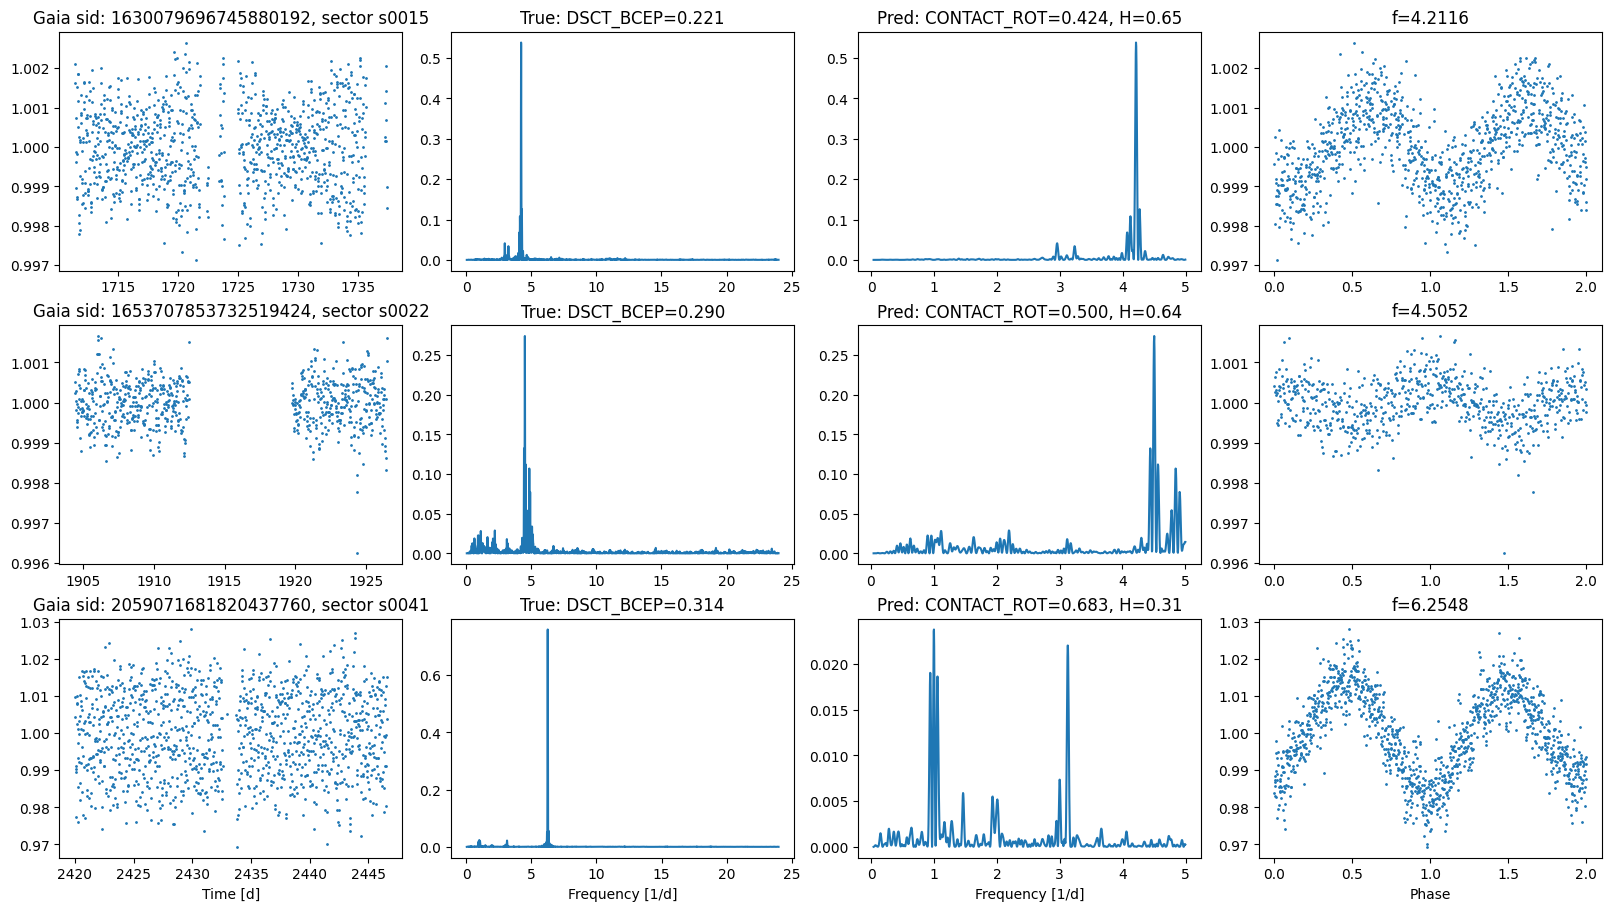

In [137]:
plot_misclasifications(true_class = 'DSCT_BCEP', pred_class = 'CONTACT_ROT', max_examples=10)

9
3


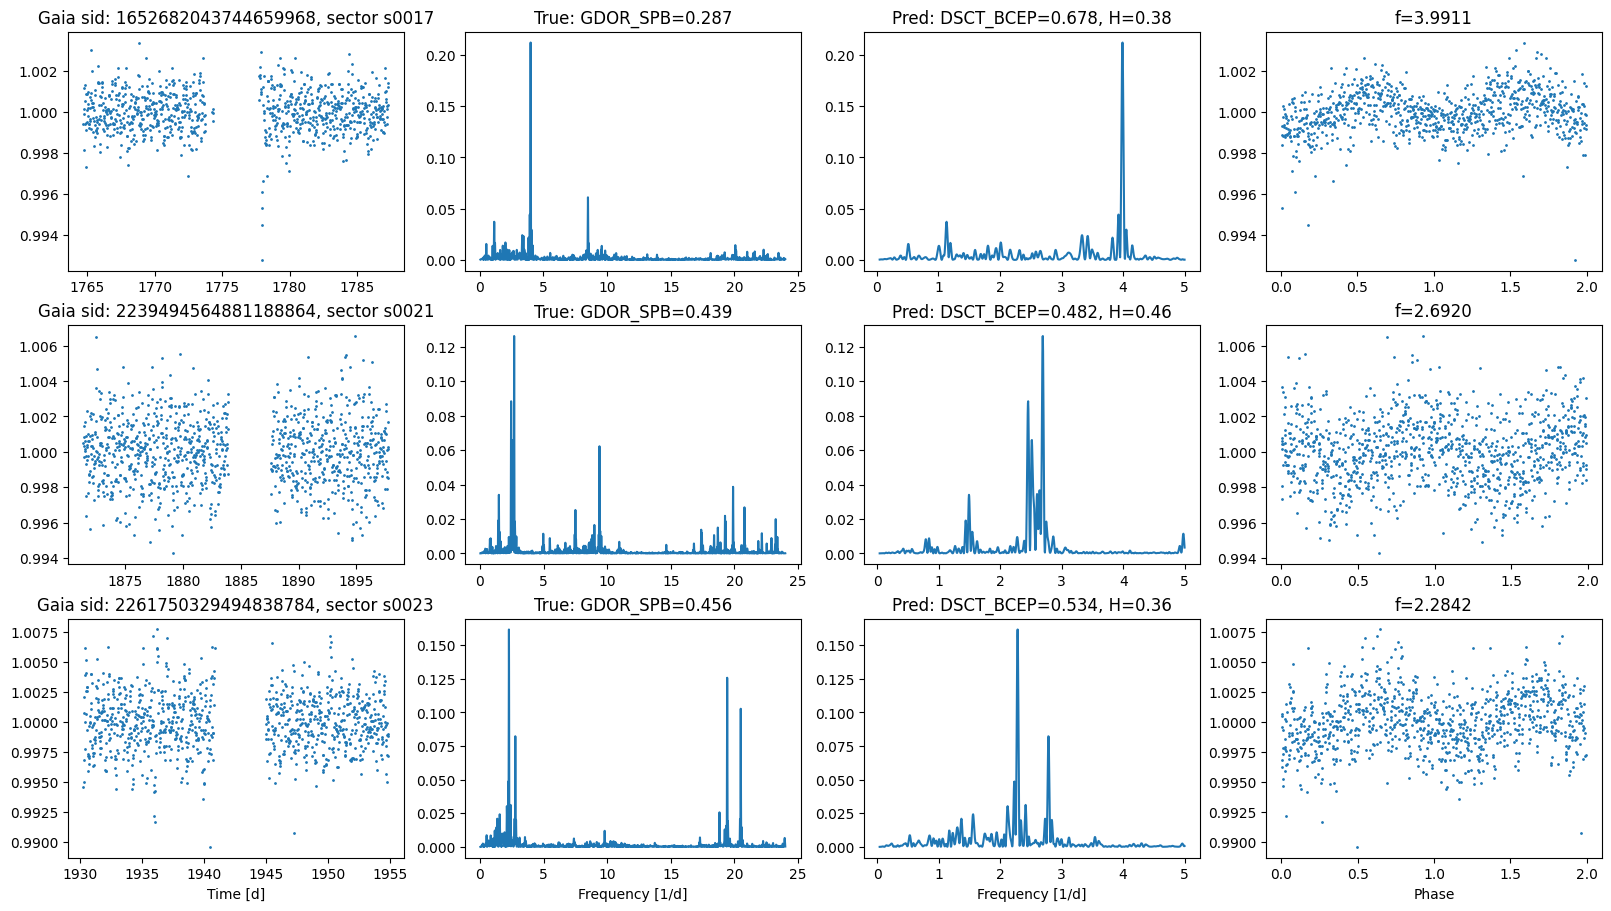

In [138]:
plot_misclasifications(true_class = 'GDOR_SPB', pred_class = 'DSCT_BCEP', max_examples=6)

7
6


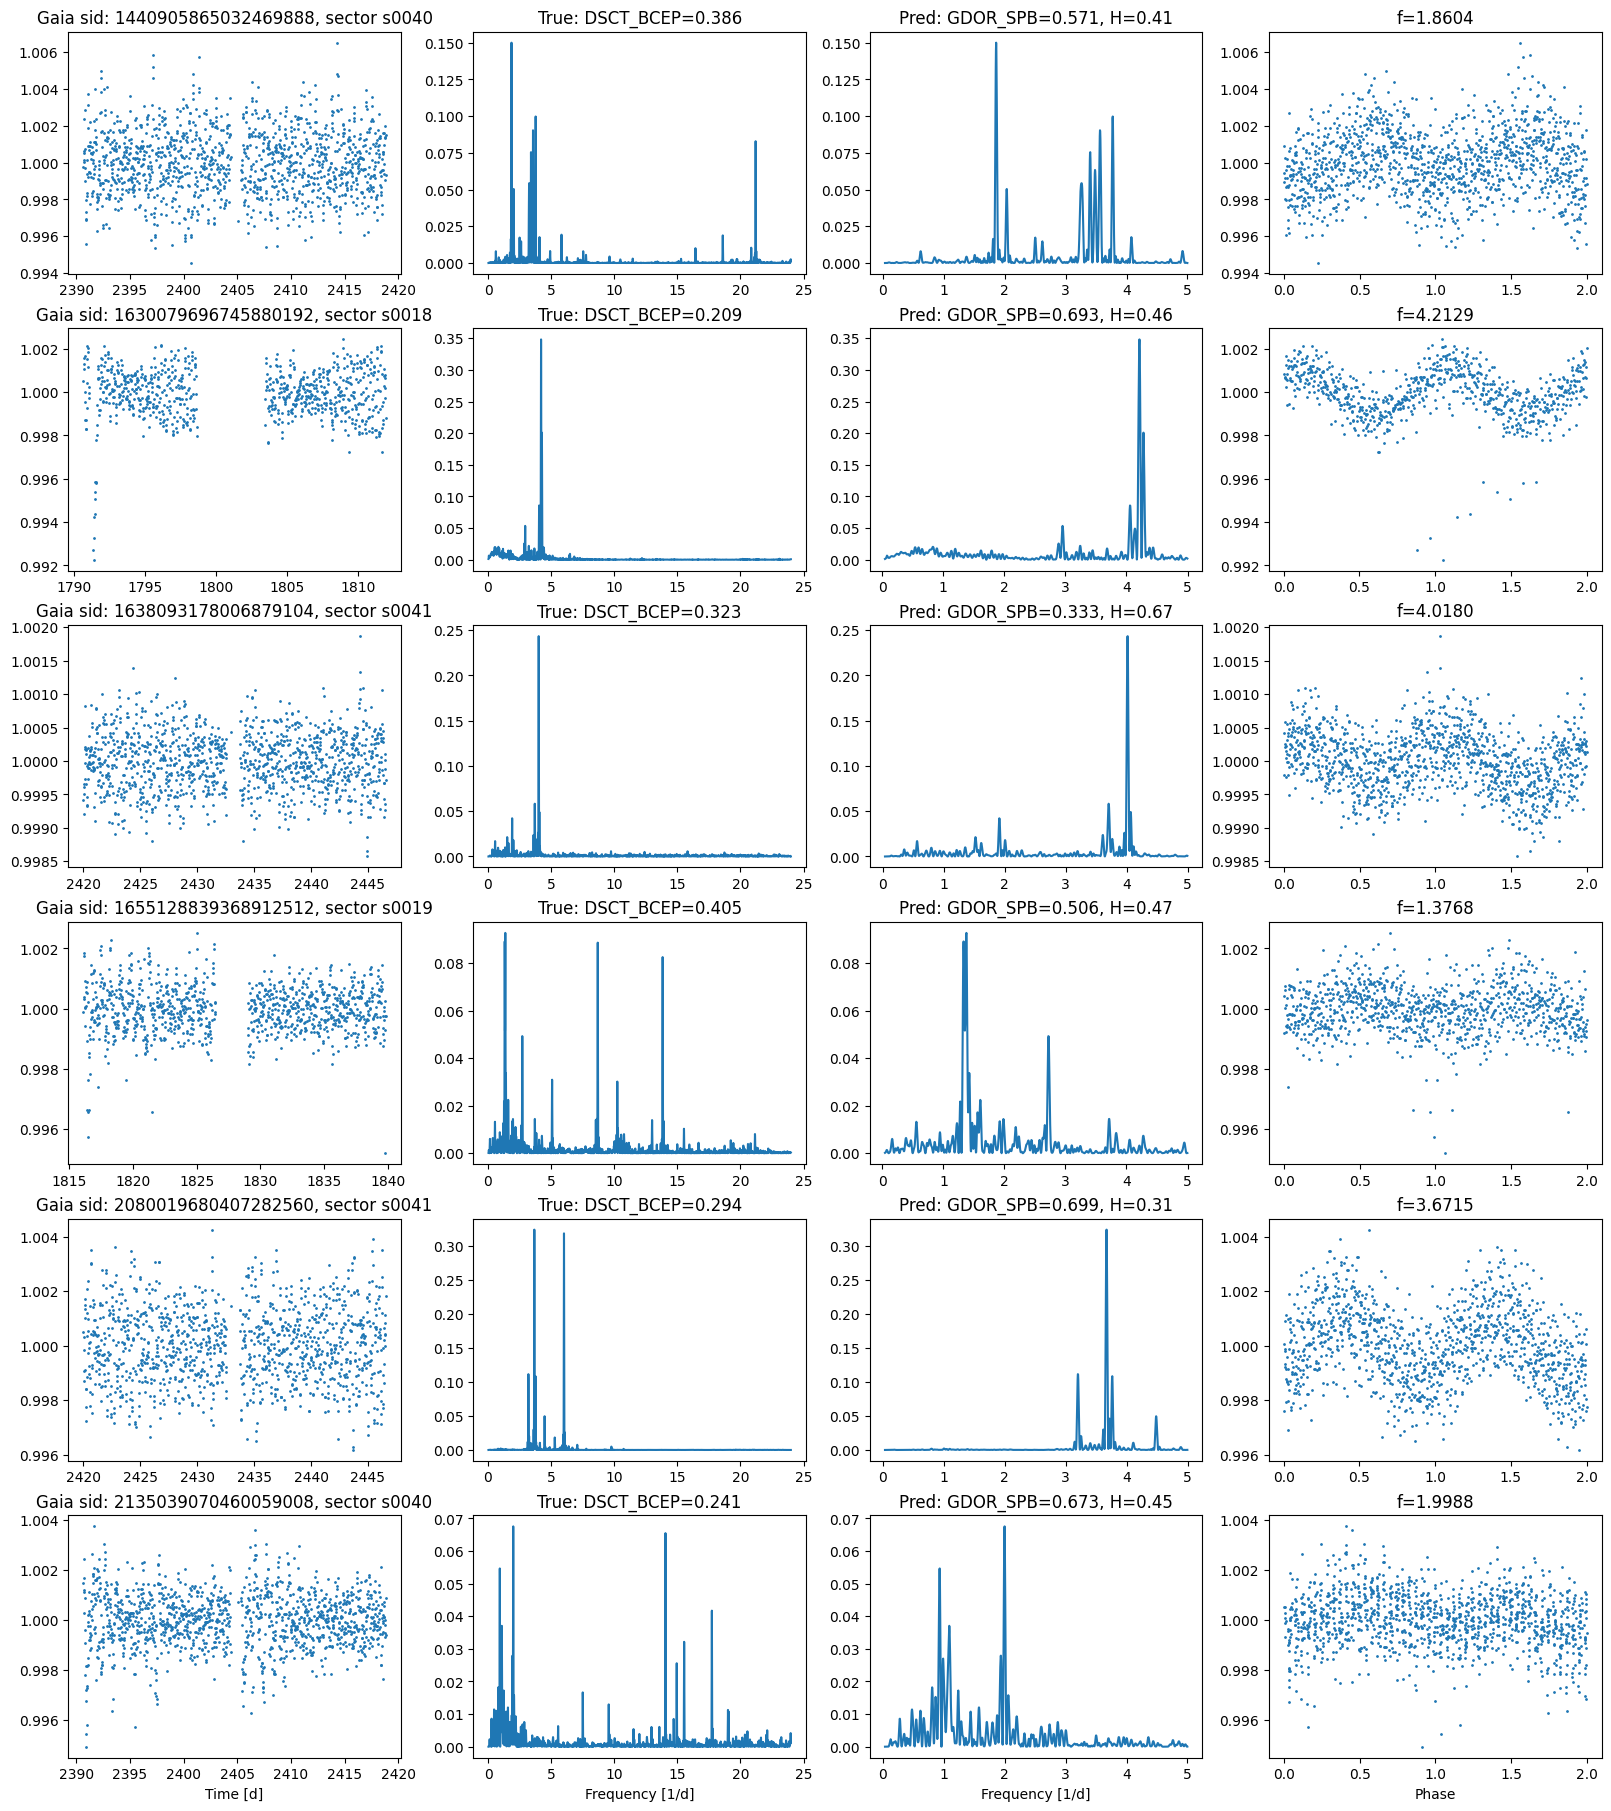

In [139]:
plot_misclasifications(true_class = 'DSCT_BCEP', pred_class = 'GDOR_SPB', max_examples=6)

In [45]:
np.where(paths_all == '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0021/cam3-ccd3/0016/6900/8799/2800/hlsp_tglc_tess_ffi_gaiaid-1669008799280057984-s0021-cam3-ccd3_tess_v1_llc.fits')[0]

array([21803])

In [92]:
best_pipe = clf.best_estimator_
xgb = best_pipe.named_steps["classifier"]

i = 21803
x_row = X_all[i, :].reshape(1, -1)

rng = np.random.default_rng(1234)
bg_idx = rng.choice(len(X_fit), size=min(200, len(X_fit)), replace=False)
X_bg = X_fit[bg_idx]
explainer = shap.explainers.Permutation(xgb.predict_proba, X_bg, feature_names=X_names)
explanation = explainer(x_row)
shap_values = explanation.values

/tmp/ipykernel_858197/179185969.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanation, X_test[:100,:], class_names=le.classes_)


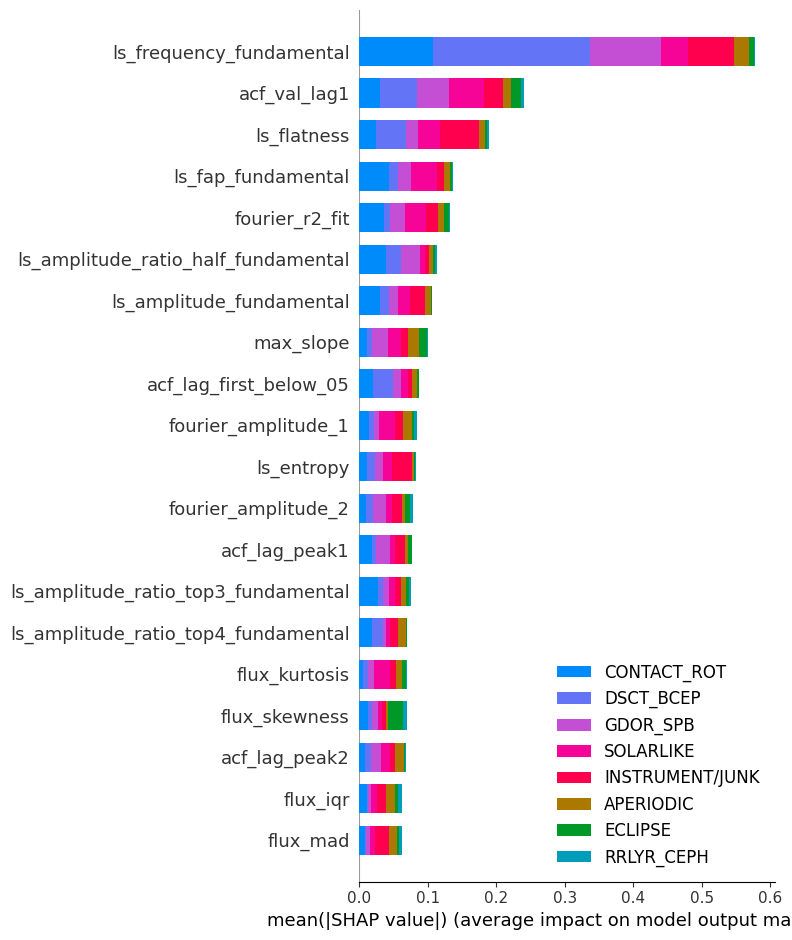

In [105]:
shap.summary_plot(explanation, X_test[:100,:], class_names=le.classes_)


PermutationExplainer explainer: 101it [00:46,  1.71it/s]                                                                                                                                                             


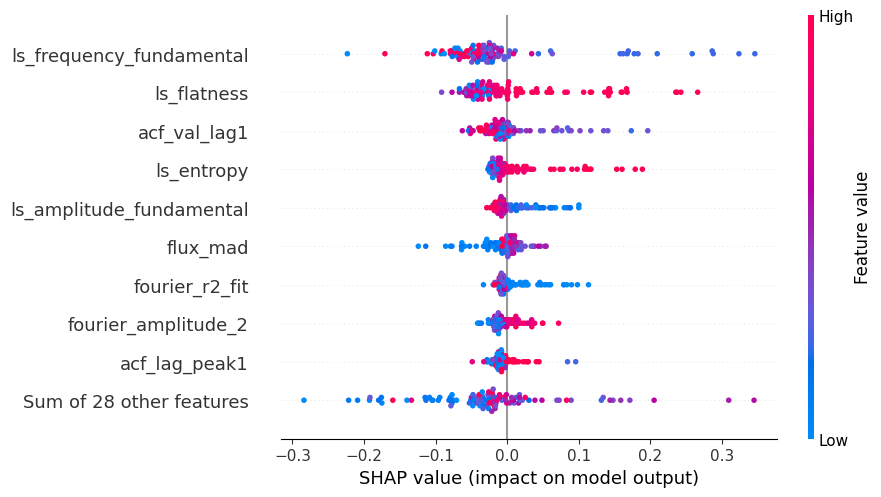

In [103]:
explanation = explainer(X_test[:100, :])
shap.plots.beeswarm(explanation[:, :, 5])

In [99]:
le.inverse_transform(xgb.predict(x_row))

array(['INSTRUMENT/JUNK'], dtype=object)

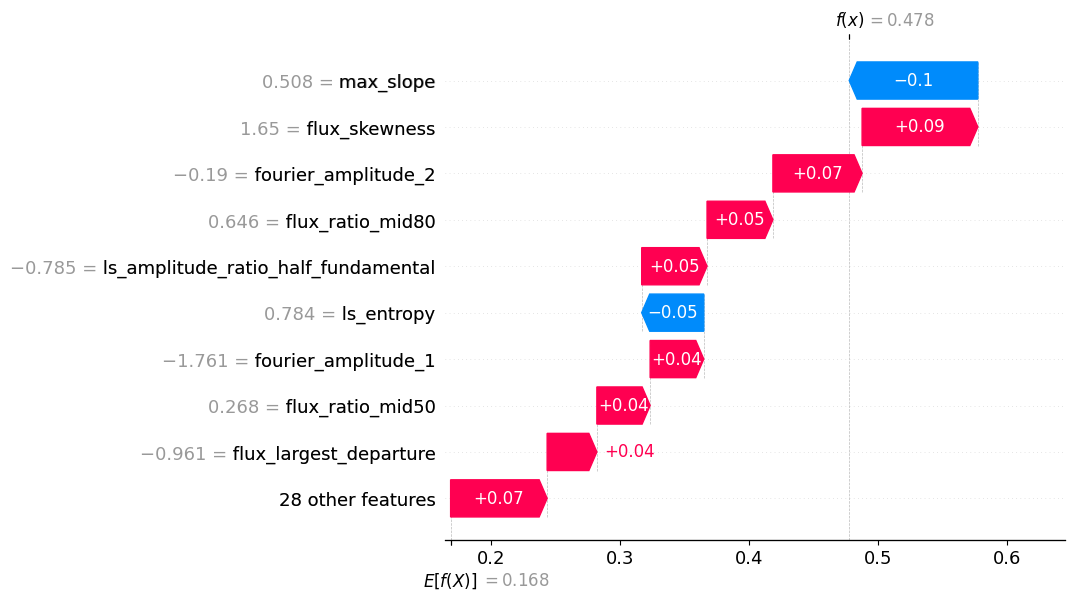

In [97]:
shap.plots.waterfall(explanation[0, :, xgb.predict_proba(x_row).argmax()])

29
29
/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0021/cam3-ccd3/0016/6900/8799/2800/hlsp_tglc_tess_ffi_gaiaid-1669008799280057984-s0021-cam3-ccd3_tess_v1_llc.fits
/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam1-ccd3/0018/5718/7083/3466/hlsp_tglc_tess_ffi_gaiaid-1857187083346647936-s0015-cam1-ccd3_tess_v1_llc.fits
/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam1-ccd2/0018/6954/6453/0358/hlsp_tglc_tess_ffi_gaiaid-1869546453035844608-s0015-cam1-ccd2_tess_v1_llc.fits
/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam1-ccd1/0018/7231/9215/2002/hlsp_tglc_tess_ffi_gaiaid-1872319215200210944-s0015-cam1-ccd1_tess_v1_llc.fits
/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0016/cam1-ccd2/0019/6779/1424/7485/hlsp_tglc_tess_ffi_gaiaid-1967791424748562432-s0016-cam1-ccd2_tess_v1_llc.fits
/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam1-ccd1/0019/7872/2052/1131/hlsp_tglc_tess_ffi_gaiaid-1978722052113121536-s0015-cam1-ccd1_tess_v1_llc.fits


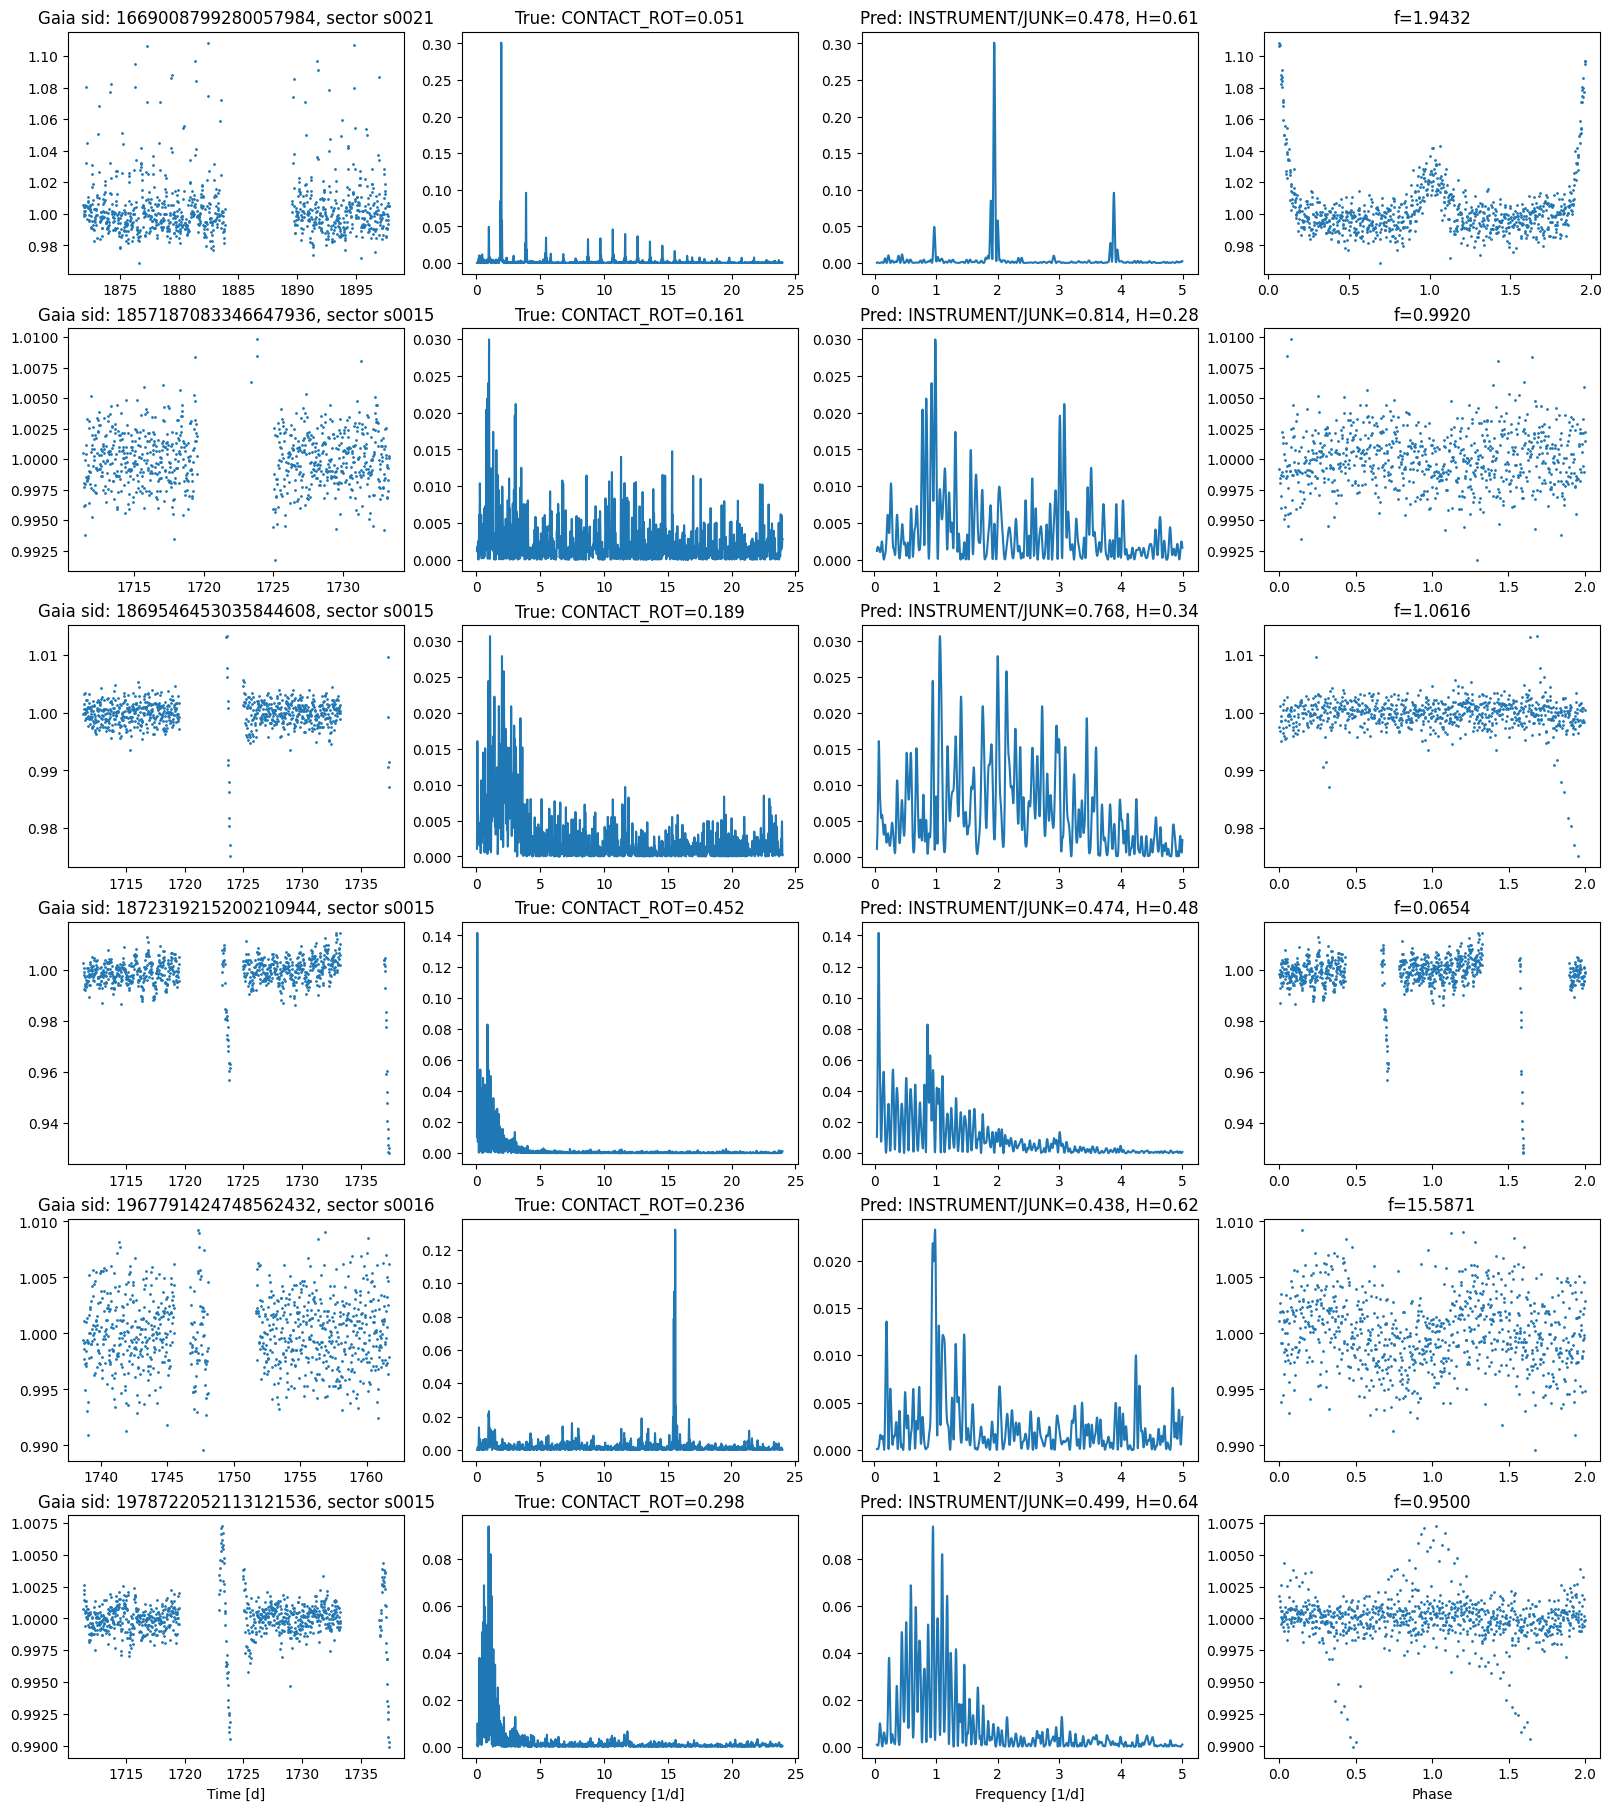

In [44]:
plot_misclasifications(true_class = 'CONTACT_ROT', pred_class = 'INSTRUMENT/JUNK', max_examples=6, verbose=True)

19
18


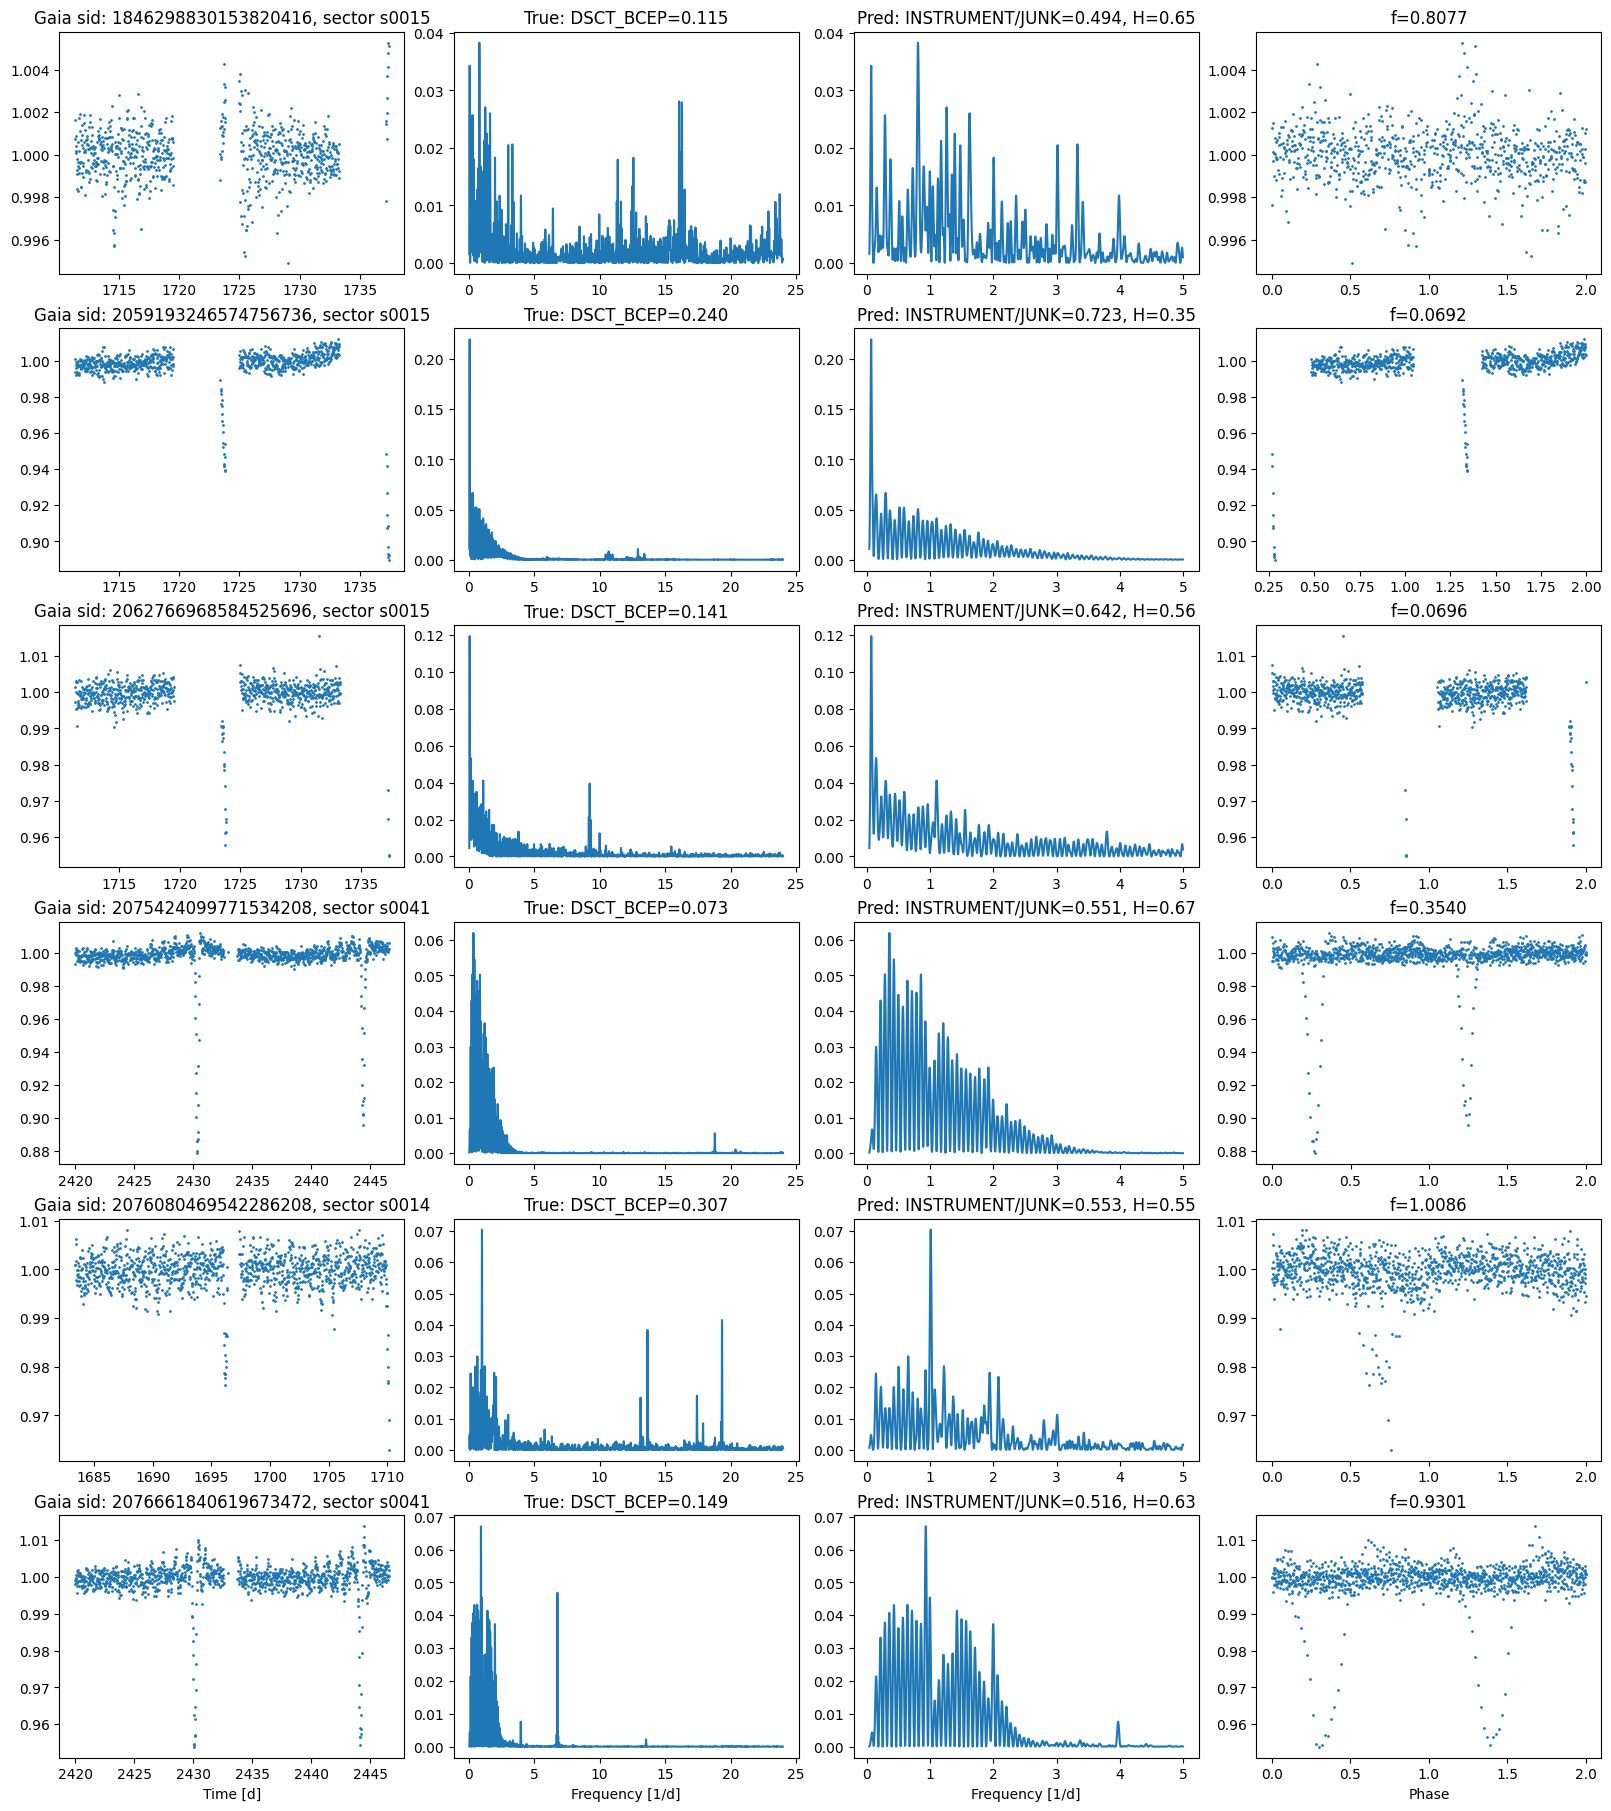

In [142]:
plot_misclasifications(true_class = 'DSCT_BCEP', pred_class = 'INSTRUMENT/JUNK', max_examples=6)

5
5


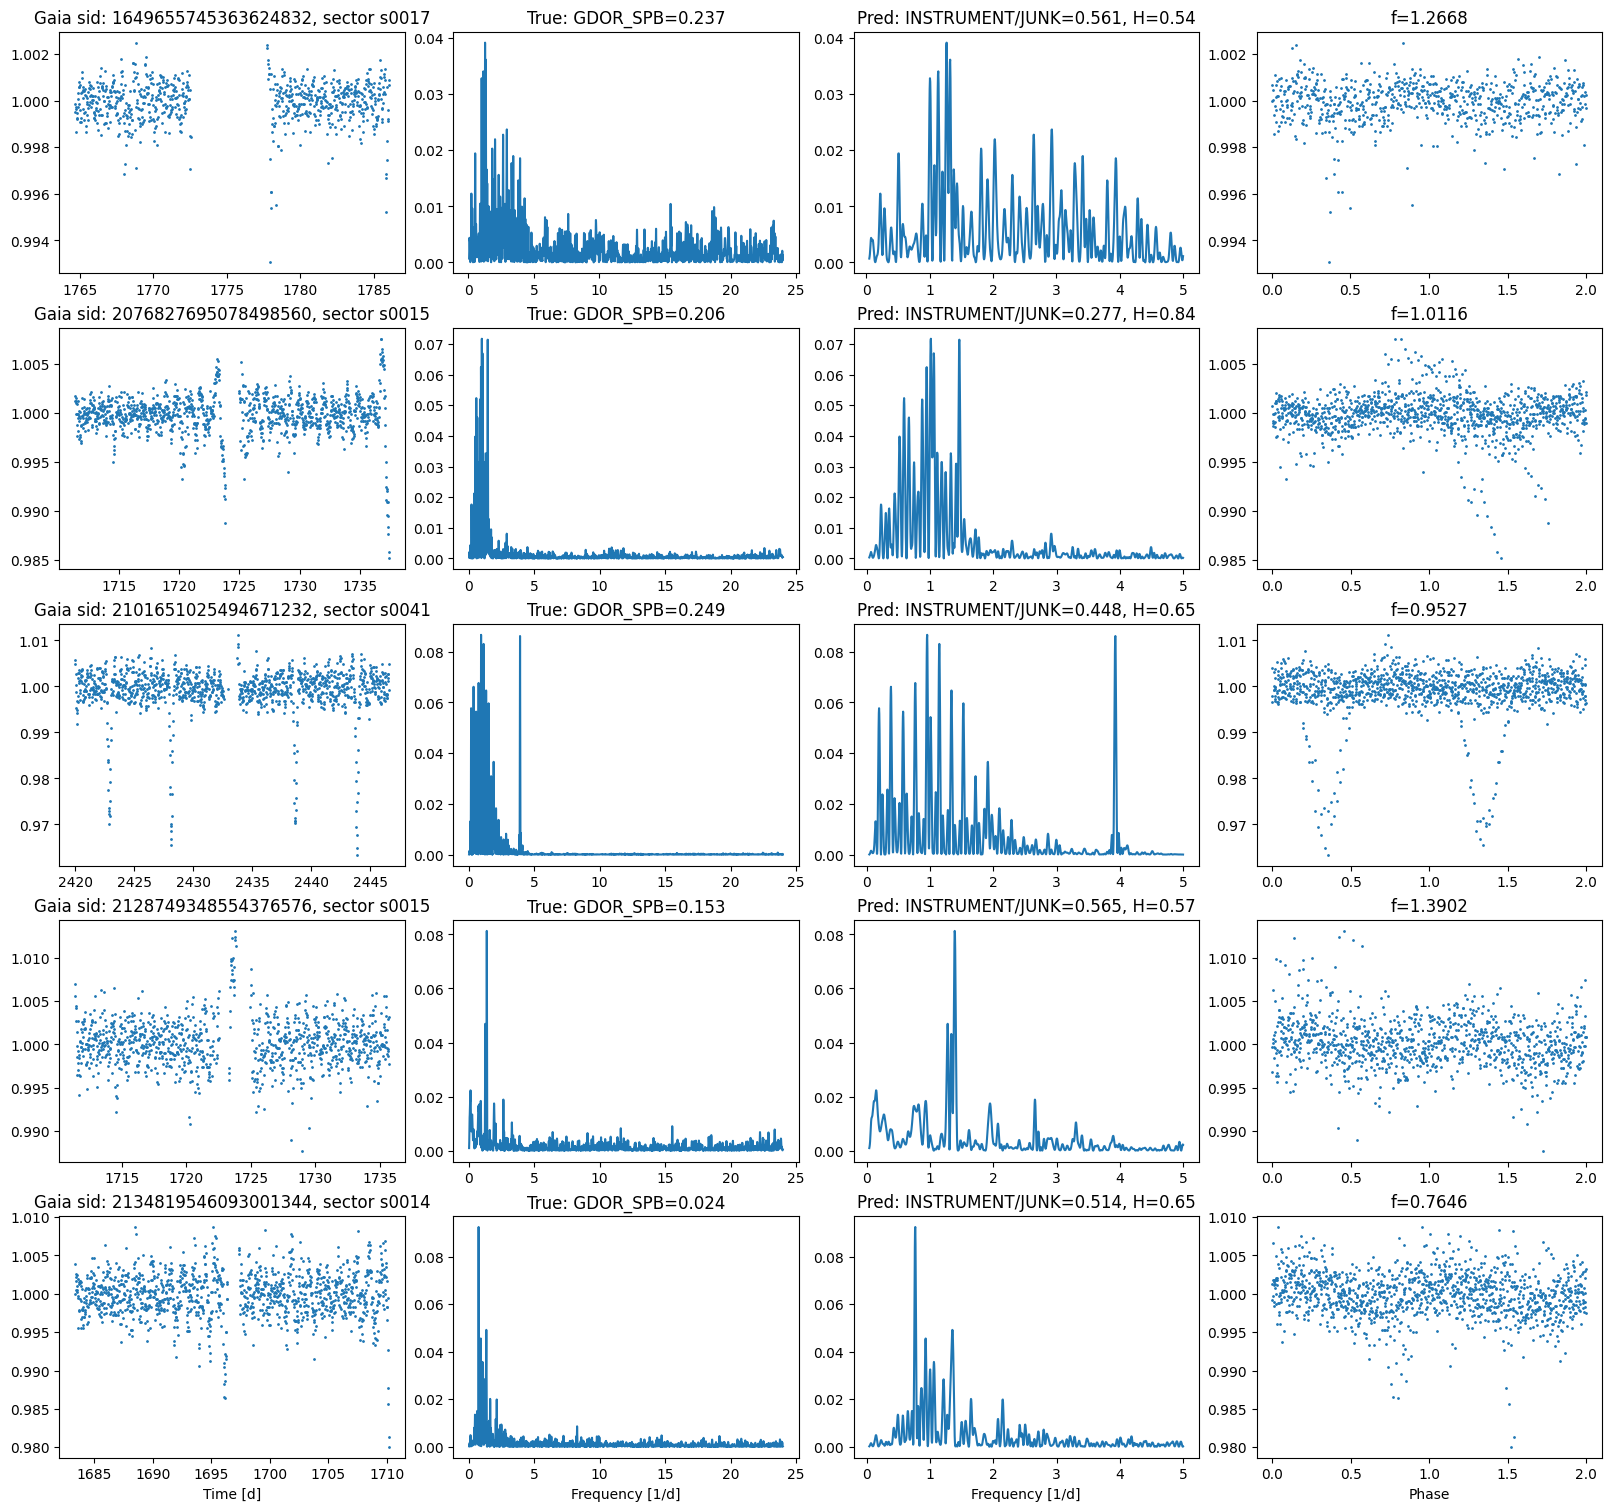

In [143]:
plot_misclasifications(true_class = 'GDOR_SPB', pred_class = 'INSTRUMENT/JUNK', max_examples=6)

# Pathological cases

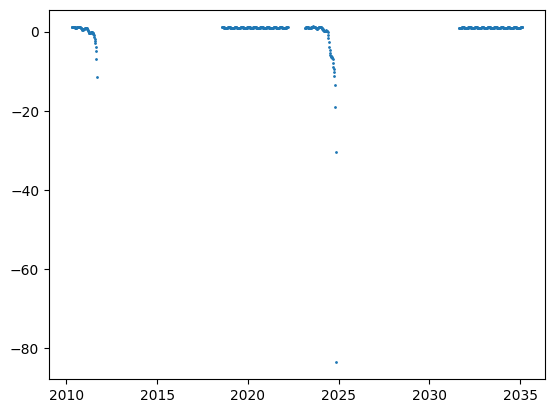

In [4]:
# Light curve completely filtered by outlier processing
from light_curves import read_fits_lc

time, flux, sector = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0026/cam1-ccd1/0020/9288/9154/7721/hlsp_tglc_tess_ffi_gaiaid-2092889154772199168-s0026-cam1-ccd1_tess_v1_llc.fits',
)
plt.scatter(time, flux, s=1)


In [20]:
time[100] -time[0]

np.float64(2.083361078711505)

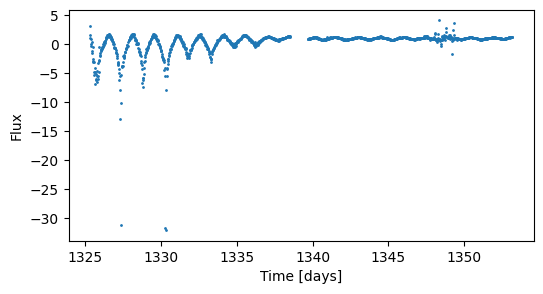

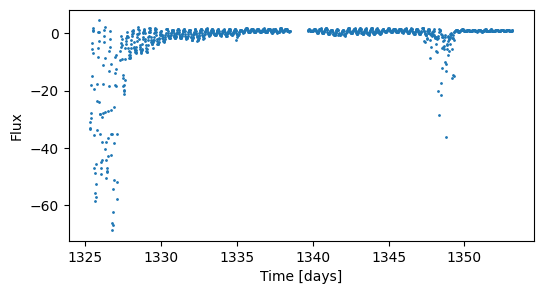

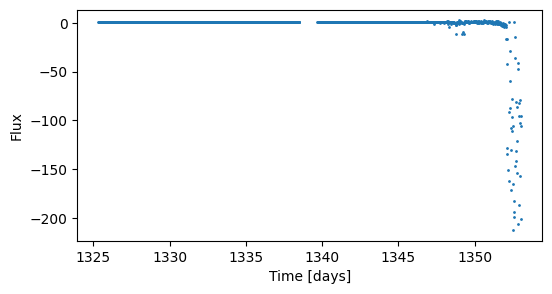

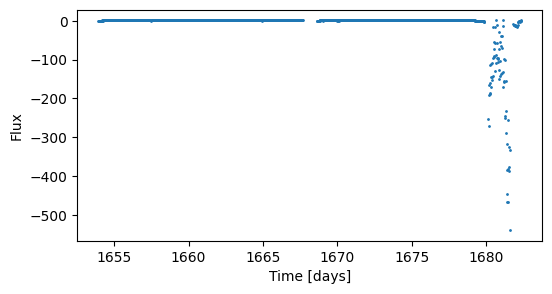

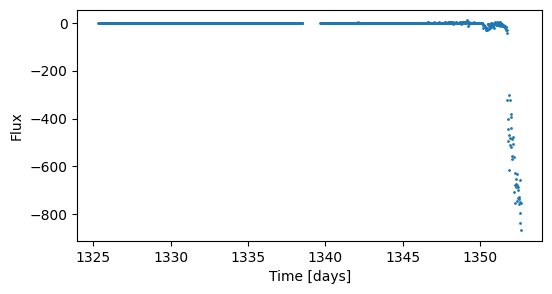

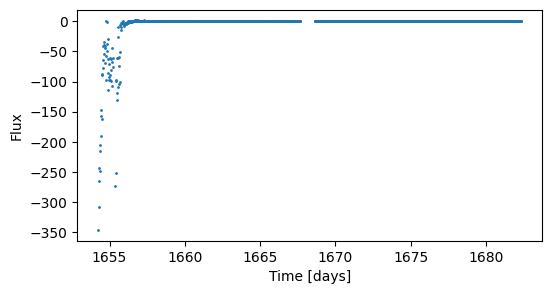

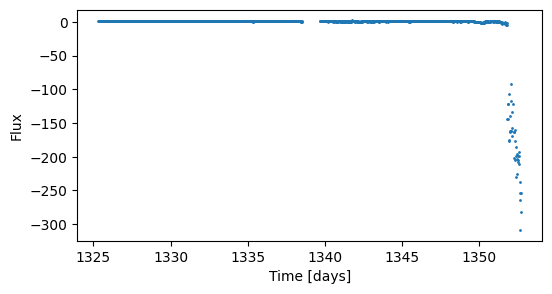

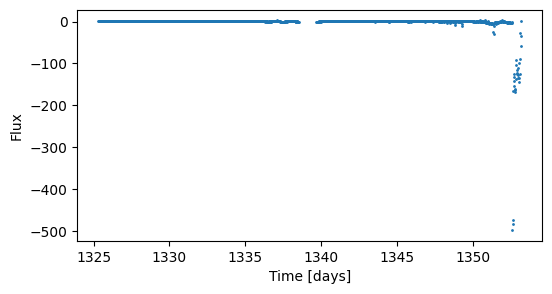

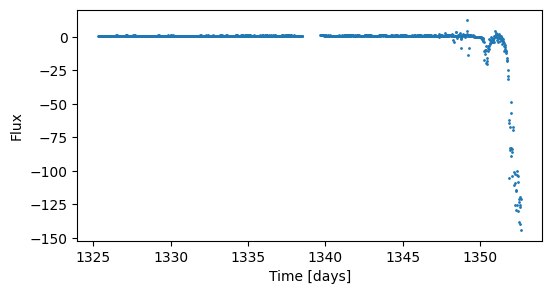

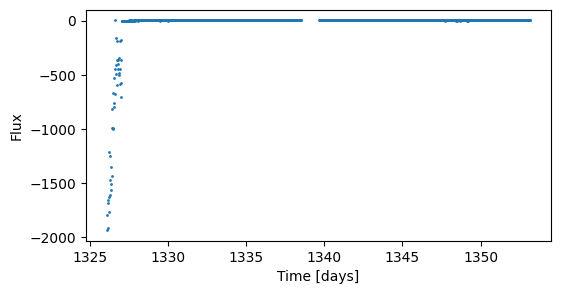

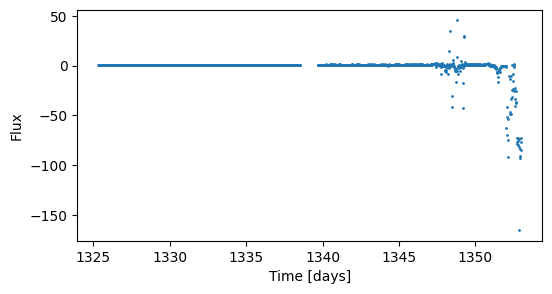

In [19]:
for path in ['/STER/mamsie/tess/TIC/plato_fov/s0001/cam3-ccd4/0046/7099/1961/9389/hlsp_tglc_tess_ffi_gaiaid-4670991961938978304-s0001-cam3-ccd4_tess_v1_llc.fits',
             '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd4/0047/5810/5615/3752/hlsp_tglc_tess_ffi_gaiaid-4758105615375228544-s0001-cam4-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd2/0046/5790/3238/1587/hlsp_tglc_tess_ffi_gaiaid-4657903238158746112-s0001-cam4-ccd2_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0013/cam4-ccd3/0054/8082/2201/8132/hlsp_tglc_tess_ffi_gaiaid-5480822201813277824-s0013-cam4-ccd3_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd4/0054/7777/4046/3438/hlsp_tglc_tess_ffi_gaiaid-5477774046343845632-s0001-cam4-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0013/cam4-ccd4/0047/5593/4629/6767/hlsp_tglc_tess_ffi_gaiaid-4755934629676773120-s0013-cam4-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd3/0052/9074/0968/0683/hlsp_tglc_tess_ffi_gaiaid-5290740968068328192-s0001-cam4-ccd3_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd3/0052/8076/9286/6578/hlsp_tglc_tess_ffi_gaiaid-5280769286657812864-s0001-cam4-ccd3_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd4/0054/9453/2008/0039/hlsp_tglc_tess_ffi_gaiaid-5494532008003954048-s0001-cam4-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd4/0055/0055/5308/7939/hlsp_tglc_tess_ffi_gaiaid-5500555308793904640-s0001-cam4-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0001/cam4-ccd1/0046/5881/1331/6401/hlsp_tglc_tess_ffi_gaiaid-4658811331640134784-s0001-cam4-ccd1_tess_v1_llc.fits']:

    time, flux, sector = read_fits_lc(path)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.scatter(time, flux, s=1)
    ax.set_xlabel('Time [days]')
    ax.set_ylabel('Flux')

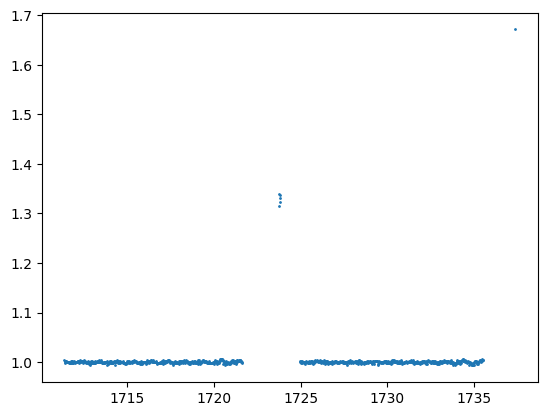

In [5]:
# Examples of extreme kurtosis

time, flux, sector = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5667/2589/6237/hlsp_tglc_tess_ffi_gaiaid-1556672589623717632-s0015-cam4-ccd4_tess_v1_llc.fits',
)
plt.scatter(time, flux, s=1)

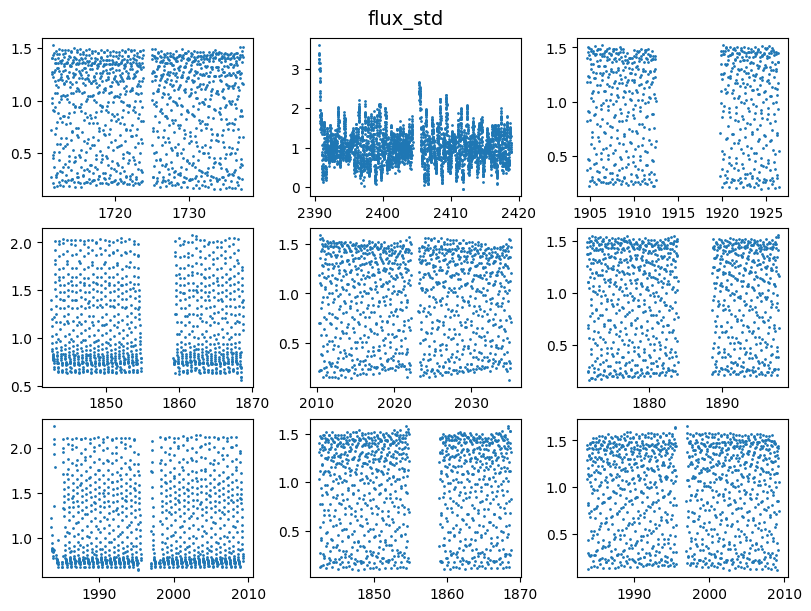

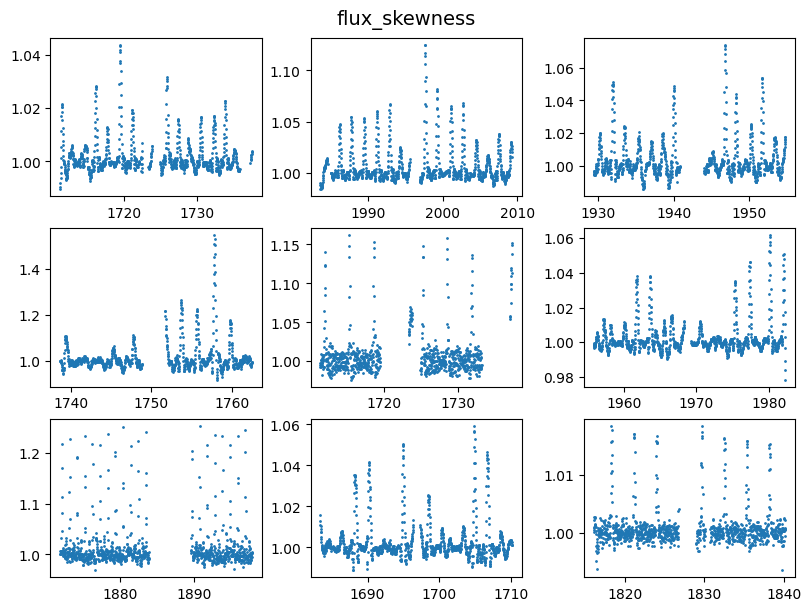

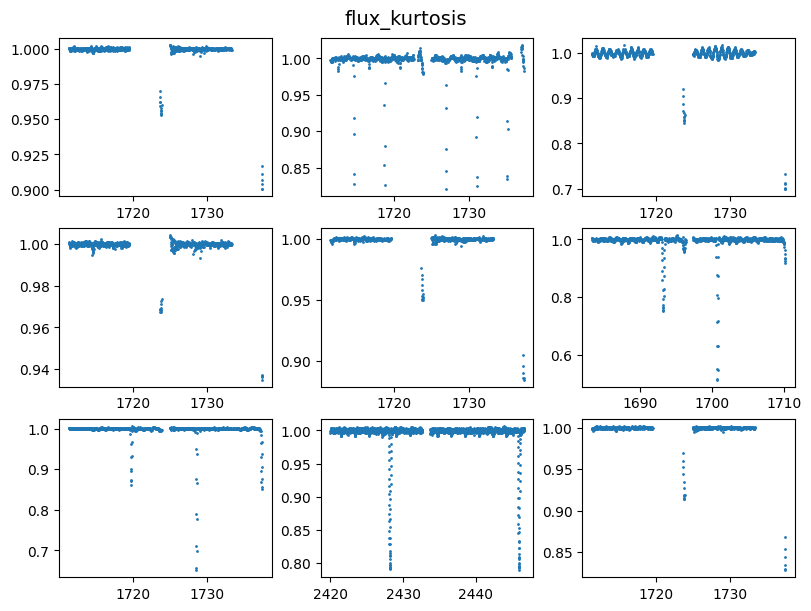

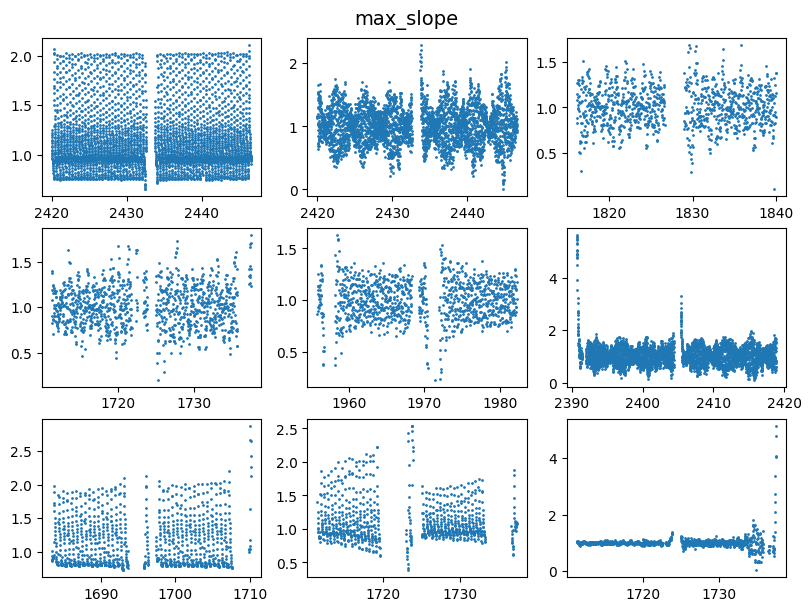

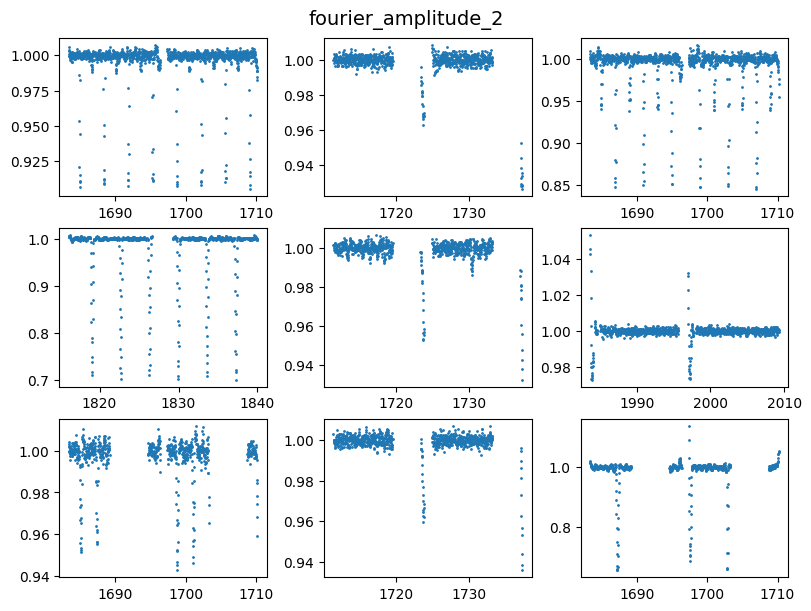

In [13]:
# Examples of light curve with extreme values of certain features

extreme_cols = ['flux_std', 'flux_skewness', 'flux_kurtosis', 'max_slope', 'fourier_amplitude_2']
for col in extreme_cols:
    fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
    for path, ax in zip(df_training_features.sort(col).tail(9)['path'].to_list(), axs.ravel()):
        time, flux, _ = read_fits_lc(path)
        ax.scatter(time, flux, s=1)
    fig.suptitle(col, fontsize=14)

In [ ]:
# Examples of light curve with extreme values of certain features

extreme_cols = ['flux_std', 'flux_skewness', 'flux_kurtosis', 'max_slope', 'fourier_amplitude_2']
for col in extreme_cols:
    fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
    for path, ax in zip(df_training_features.sort(col).head(9)['path'].to_list(), axs.ravel()):
        time, flux, _ = read_fits_lc(path)
        ax.scatter(time, flux, s=1)
    fig.suptitle(col, fontsize=14)